In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns

print("Python version:", sys.version)
print("Python executable:", sys.executable)

print("\nPackage versions:")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

print("\nEnvironment check: PASSED")

Python version: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Smart_Traffic_Congestion_Prediction\.venv\Scripts\python.exe

Package versions:
pandas: 3.0.6
numpy: 2.5.3
matplotlib: 3.11.2
seaborn: 0.13.2

Environment check: PASSED


# Smart Traffic Congestion Prediction Using Machine Learning

## Project Overview

Traffic congestion is a major problem in urban areas because it increases travel
time, fuel consumption, and delays for road users. Predicting traffic conditions
from historical traffic data can help in understanding traffic patterns and
support intelligent transportation systems.

This project focuses on analyzing traffic data from New Delhi and developing
machine learning models for traffic congestion prediction.

The project follows a statistical machine learning approach involving:

- Data inspection and understanding
- Data preprocessing and cleaning
- Exploratory Data Analysis (EDA)
- Feature engineering
- Data leakage analysis
- Chronological train-test splitting
- Linear Regression
- Polynomial Regression
- Random Forest Regression
- Evaluation using MAE, RMSE, and R²
- Model comparison
- A simple prediction prototype

The dataset used in this project is the **New Delhi Traffic Probe &
Analytics Dataset (2024)**.

The target variable and final predictor variables will be selected only after
carefully examining the actual dataset structure and checking for possible
data leakage.

## 1. Import Required Libraries

The following libraries are used throughout the project:

- **pandas**: data manipulation and analysis
- **numpy**: numerical computation
- **matplotlib**: data visualization
- **seaborn**: statistical visualization

Additional machine learning libraries will be imported later when the modeling
stage begins.

In [2]:
# 1. IMPORT REQUIRED LIBRARIES

# Pandas is used for creating and manipulating DataFrames.
import pandas as pd

# NumPy provides numerical and mathematical operations.
import numpy as np

# Matplotlib is used for creating plots and charts.
import matplotlib.pyplot as plt

# Seaborn provides additional statistical visualization tools.
import seaborn as sns

# Display settings

# Display more columns when inspecting DataFrames.
pd.set_option("display.max_columns", None)

# Make DataFrame output easier to read.
pd.set_option("display.width", 120)

# Set a consistent visual style for later plots.
sns.set_theme(style="whitegrid")


print("Required libraries imported successfully.")

Required libraries imported successfully.


## 2. Dataset Path and Initial File Verification

The dataset is provided as a ZIP archive containing multiple data sources,
including daily traffic probe-count GeoJSON files, CSV summary files, and
JSON files containing aggregated traffic information.

Before loading the data, we first verify that the expected ZIP file exists
and inspect its contents.

In [3]:
# 2. DATASET PATH AND INITIAL FILE VERIFICATION

# Path is used to work with file and folder locations safely.
from pathlib import Path

# zipfile allows us to inspect the ZIP archive without extracting it.
import zipfile


# Define the project directory

# The current working directory should be our project folder.
PROJECT_DIR = Path.cwd()

# Name of the dataset ZIP file.
ZIP_PATH = PROJECT_DIR / "archive (1).zip"


# Verify that the dataset exists

print("Project directory:")
print(PROJECT_DIR)

print("\nDataset path:")
print(ZIP_PATH)


if ZIP_PATH.exists():
    print("\nDataset file found successfully.")
    print(
        f"Dataset size: "
        f"{ZIP_PATH.stat().st_size / (1024 * 1024):.2f} MB"
    )
else:
    raise FileNotFoundError(
        f"Dataset ZIP file was not found at: {ZIP_PATH}"
    )


# Inspect the ZIP contents

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    # Get all files stored inside the ZIP archive.
    all_files = [
        file_name
        for file_name in zip_file.namelist()
        if not file_name.endswith("/")
    ]

    print(f"\nTotal files inside ZIP: {len(all_files)}")

    print("\nFirst 10 files:")
    print("-" * 70)

    for file_name in all_files[:10]:
        print(file_name)

Project directory:
c:\Smart_Traffic_Congestion_Prediction

Dataset path:
c:\Smart_Traffic_Congestion_Prediction\archive (1).zip

Dataset file found successfully.
Dataset size: 63.09 MB

Total files inside ZIP: 33

First 10 files:
----------------------------------------------------------------------
new_delhi_traffic_dataset/README.md
new_delhi_traffic_dataset/facility/features_geopkg.json
new_delhi_traffic_dataset/geojson/new_delhi.json
new_delhi_traffic_dataset/global_metrics/2024_city_rush_hour.json
new_delhi_traffic_dataset/global_metrics/2024_urban_rush_hour.json
new_delhi_traffic_dataset/global_metrics/new_delhi_2024_city_traffic.json
new_delhi_traffic_dataset/global_metrics/new_delhi_2024_urban_traffic.json
new_delhi_traffic_dataset/probe_counts/geojson/new_delhi__2024-08-11_to_2024-08-11_.geojson
new_delhi_traffic_dataset/probe_counts/geojson/new_delhi__2024-08-12_to_2024-08-12_.geojson
new_delhi_traffic_dataset/probe_counts/geojson/new_delhi__2024-08-13_to_2024-08-13_.geojson


## 3. Load and Flatten the Hourly Traffic Data

The main traffic observations are stored in 20 daily GeoJSON files.

Each daily file contains road-segment features, and each road segment contains
24 hourly records inside the `segmentProbeCounts` field.

For machine learning, we need a tabular dataset in which each row represents
one road segment for one date and one hour.

The resulting table will contain road characteristics, time information, and
the corresponding probe count.

In [4]:
# 3. LOAD AND FLATTEN THE HOURLY TRAFFIC DATA

# JSON is used to read the GeoJSON files stored inside the ZIP archive.
import json

# Identify the daily probe-count GeoJSON files

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    # Select only the daily probe-count GeoJSON files.
    probe_files = sorted(
        file_name
        for file_name in zip_file.namelist()
        if "probe_counts/geojson/" in file_name
        and file_name.endswith(".geojson")
    )

print(f"Number of daily probe-count files: {len(probe_files)}")


# Create an empty list to store flattened observations

# Each dictionary added to this list will become one row
# in our final DataFrame.
traffic_records = []


# Process each daily GeoJSON file

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    for file_number, file_name in enumerate(probe_files, start=1):

        # Read the GeoJSON file from inside the ZIP archive.
        with zip_file.open(file_name) as file:
            geojson_data = json.load(file)

        # Extract the date from the filename.
        #
        # Example filename:
        # new_delhi__2024-08-11_to_2024-08-11_.geojson
        #
        # The date is located between "__" and "_to_".
        file_name_only = Path(file_name).name
        date_text = file_name_only.split("__")[1].split("_to_")[0]

        # Process every feature in the GeoJSON file.
        for feature in geojson_data["features"]:

            properties = feature.get("properties", {})

            # The first feature contains metadata rather than
            # an individual road segment.
            if "segmentId" not in properties:
                continue

            # Extract road-segment information.
            segment_id = properties.get("segmentId")
            new_segment_id = properties.get("newSegmentId")
            speed_limit = properties.get("speedLimit")
            frc = properties.get("frc")
            street_name = properties.get("streetName")
            distance = properties.get("distance")

            # Extract the 24 hourly probe-count records.
            hourly_records = properties.get(
                "segmentProbeCounts",
                []
            )

            # Create one row for each hourly observation.
            for hourly_record in hourly_records:

                traffic_records.append({
                    "date": date_text,
                    "segmentId": segment_id,
                    "newSegmentId": new_segment_id,
                    "speedLimit": speed_limit,
                    "frc": frc,
                    "streetName": street_name,
                    "distance": distance,
                    "timeSet": hourly_record.get("timeSet"),
                    "dateRange": hourly_record.get("dateRange"),
                    "probeCount": hourly_record.get("probeCount")
                })

        # Display progress so that processing can be monitored.
        print(
            f"Processed {file_number}/{len(probe_files)}: "
            f"{file_name_only}"
        )


# Convert the flattened records into a DataFrame

traffic_df = pd.DataFrame(traffic_records)


# Display basic information about the flattened dataset

print("\n" + "=" * 70)
print("FLATTENING COMPLETED")
print("=" * 70)

print("\nDataFrame shape:")
print(traffic_df.shape)

print("\nColumns:")
print(list(traffic_df.columns))

print("\nFirst 5 rows:")
display(traffic_df.head())

Number of daily probe-count files: 20
Processed 1/20: new_delhi__2024-08-11_to_2024-08-11_.geojson
Processed 2/20: new_delhi__2024-08-12_to_2024-08-12_.geojson
Processed 3/20: new_delhi__2024-08-13_to_2024-08-13_.geojson
Processed 4/20: new_delhi__2024-08-14_to_2024-08-14_.geojson
Processed 5/20: new_delhi__2024-08-15_to_2024-08-15_.geojson
Processed 6/20: new_delhi__2024-08-16_to_2024-08-16_.geojson
Processed 7/20: new_delhi__2024-08-17_to_2024-08-17_.geojson
Processed 8/20: new_delhi__2024-08-18_to_2024-08-18_.geojson
Processed 9/20: new_delhi__2024-08-19_to_2024-08-19_.geojson
Processed 10/20: new_delhi__2024-08-20_to_2024-08-20_.geojson
Processed 11/20: new_delhi__2024-08-21_to_2024-08-21_.geojson
Processed 12/20: new_delhi__2024-08-22_to_2024-08-22_.geojson
Processed 13/20: new_delhi__2024-08-23_to_2024-08-23_.geojson
Processed 14/20: new_delhi__2024-08-24_to_2024-08-24_.geojson
Processed 15/20: new_delhi__2024-08-25_to_2024-08-25_.geojson
Processed 16/20: new_delhi__2024-08-26_to

,date,segmentId,newSegmentId,speedLimit,frc,streetName,distance,timeSet,dateRange,probeCount
0,2024-08-11,-13560111507837,-00004e30-3400-0400-0000-0000008bad86,45,6,Ghata Masjid Road,20.87,2,1,4
1,2024-08-11,-13560111507837,-00004e30-3400-0400-0000-0000008bad86,45,6,Ghata Masjid Road,20.87,3,1,2
2,2024-08-11,-13560111507837,-00004e30-3400-0400-0000-0000008bad86,45,6,Ghata Masjid Road,20.87,4,1,1
3,2024-08-11,-13560111507837,-00004e30-3400-0400-0000-0000008bad86,45,6,Ghata Masjid Road,20.87,5,1,0
4,2024-08-11,-13560111507837,-00004e30-3400-0400-0000-0000008bad86,45,6,Ghata Masjid Road,20.87,6,1,0


## 4. Basic Verification of the Flattened Dataset

The nested traffic data has now been converted into a tabular DataFrame.

Before performing any cleaning or feature engineering, we verify:

- the number of observations and variables,
- the data types of each column,
- the date range,
- the number of unique road segments,
- the number of unique hourly values,
- and a small sample of the data.

This verification helps ensure that the flattening process was performed correctly.

In [5]:
# 4. BASIC VERIFICATION OF THE FLATTENED DATASET

# Display the dimensions of the DataFrame

print("Number of rows:", traffic_df.shape[0])
print("Number of columns:", traffic_df.shape[1])

# Display the column names

print("\nColumn names:")
print(traffic_df.columns.tolist())


# Display the data types

print("\nData types:")
print(traffic_df.dtypes)

# Check the date range

print("\nDate range:")

print("First date:", traffic_df["date"].min())
print("Last date :", traffic_df["date"].max())

# Count unique road segments

print("\nUnique road segments:")
print(traffic_df["segmentId"].nunique())

# Count unique hourly values

print("\nUnique timeSet values:")
print(sorted(traffic_df["timeSet"].dropna().unique()))

# Count unique dateRange values

print("\nUnique dateRange values:")
print(sorted(traffic_df["dateRange"].dropna().unique()))

# Display a random sample

print("\nRandom sample of observations:")

display(
    traffic_df.sample(
        n=5,
        random_state=42
    )
)

Number of rows: 11970240
Number of columns: 10

Column names:
['date', 'segmentId', 'newSegmentId', 'speedLimit', 'frc', 'streetName', 'distance', 'timeSet', 'dateRange', 'probeCount']

Data types:
date                str
segmentId         int64
newSegmentId        str
speedLimit        int64
frc               int64
streetName          str
distance        float64
timeSet           int64
dateRange         int64
probeCount        int64
dtype: object

Date range:
First date: 2024-08-11
Last date : 2024-08-30

Unique road segments:
24938

Unique timeSet values:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]

Unique dateRange values:
[np.int64(1)]

Random sample of observations:


,date,segmentId,newSegmentId,speedLimit,frc,streetName,distance,timeSet,dateRange,probeCount
140378,2024-08-11,13560131752583,00004e30-3400-0400-0000-0000008bd540,45,3,Bahadur Shah Zafar Marg,22.11,4,1,6
7598643,2024-08-23,13560136140537,00004e30-3400-0400-0000-0000041e2df8,60,1,Mahatma Gandhi Marg,106.21,5,1,2
3998003,2024-08-17,13560180003329,00004e30-3400-0400-0000-0000041ddb18,50,2,Aurobindo Marg,4.39,13,1,479
9999141,2024-08-27,13560186642562,00004e30-3400-0400-0000-0000041fdb3e,45,4,Shaheed Jeet Singh Marg,65.83,23,1,122
9713139,2024-08-27,-13560322968706,-ff30c3d6-ca5a-4d89-844d-85695c59f6dd,50,4,Indermohan Bhardwaj Marg,91.62,5,1,13


## 5. Missing Values, Duplicates, and Numerical Summary

Before performing data cleaning, we examine the quality of the flattened
traffic dataset.

This step checks:

- Missing values in every column
- Duplicate observations
- Duplicate segment-date-hour combinations
- Basic statistics of numerical variables

We will use these results to decide whether any cleaning is actually necessary.

In [6]:
# 5. MISSING VALUES, DUPLICATES, AND NUMERICAL SUMMARY

# Check the number and percentage of missing values in each column.
missing_summary = pd.DataFrame({
    "missing_count": traffic_df.isna().sum(),
    "missing_percentage": traffic_df.isna().mean() * 100
})

print("Missing value summary:")
display(missing_summary)


# Check for completely duplicated rows.
total_duplicate_rows = traffic_df.duplicated().sum()

print("\nNumber of completely duplicated rows:")
print(total_duplicate_rows)


# Check whether the same segment, date, and hour occurs more than once.
# This is a more meaningful duplicate check for hourly traffic observations.
segment_time_duplicates = traffic_df.duplicated(
    subset=["date", "segmentId", "timeSet"]
).sum()

print("\nDuplicate date-segment-hour observations:")
print(segment_time_duplicates)


# Display descriptive statistics for numerical columns.
print("\nNumerical summary:")
display(traffic_df.describe())


# Check the minimum and maximum probe count explicitly.
print("\nProbe count range:")
print("Minimum probeCount:", traffic_df["probeCount"].min())
print("Maximum probeCount:", traffic_df["probeCount"].max())

Missing value summary:


,missing_count,missing_percentage
date,0,0.000000
segmentId,0,0.000000
newSegmentId,0,0.000000
speedLimit,0,0.000000
frc,0,0.000000
streetName,1069920,8.938167
distance,0,0.000000
timeSet,0,0.000000
dateRange,0,0.000000
probeCount,0,0.000000



Number of completely duplicated rows:
0

Duplicate date-segment-hour observations:
0

Numerical summary:


,segmentId,speedLimit,frc,distance,timeSet,dateRange,probeCount
count,1.197024e+07,1.197024e+07,1.197024e+07,1.197024e+07,1.197024e+07,11970240.0,1.197024e+07
mean,7.338541e+12,4.752751e+01,3.609993e+00,5.629097e+01,1.350000e+01,1.0,1.240317e+02
std,1.140286e+13,8.156442e+00,1.604674e+00,6.895495e+01,6.922187e+00,0.0,1.962645e+02
min,-1.356035e+13,1.800000e+01,1.000000e+00,3.500000e+00,2.000000e+00,1.0,0.000000e+00
25%,1.356011e+13,4.500000e+01,2.000000e+00,1.527000e+01,7.750000e+00,1.0,9.000000e+00
50%,1.356014e+13,5.000000e+01,4.000000e+00,3.414000e+01,1.350000e+01,1.0,4.600000e+01
75%,1.356024e+13,5.000000e+01,5.000000e+00,7.059000e+01,1.925000e+01,1.0,1.480000e+02
max,1.356035e+13,8.000000e+01,6.000000e+00,1.353770e+03,2.500000e+01,1.0,2.766000e+03



Probe count range:
Minimum probeCount: 0
Maximum probeCount: 2766


## 6. Investigating Missing Street Names and Time Information

The initial data-quality analysis identified missing values in `streetName`,
while the main traffic measurement field, `probeCount`, contains no missing
values.

Instead of immediately removing observations with missing street names, we
first investigate whether the missingness is associated with particular road
segments.

We also verify the meaning of the `timeSet` values using the original dataset
metadata before converting them into hour-based features.

In [7]:
# 6. INVESTIGATE MISSING STREET NAMES AND TIME INFORMATION

# Count observations with and without a street name.
street_name_missing = traffic_df["streetName"].isna().sum()
street_name_available = traffic_df["streetName"].notna().sum()

print("Street name availability:")
print(f"Missing street names : {street_name_missing:,}")
print(f"Available street names: {street_name_available:,}")


# Count how many unique road segments have at least one missing street name.
segments_with_missing_names = traffic_df.loc[
    traffic_df["streetName"].isna(),
    "segmentId"
].nunique()

print("\nUnique segments with missing street names:")
print(segments_with_missing_names)


# Check whether those segments have a street name available
# in other observations.
segment_name_check = (
    traffic_df
    .groupby("segmentId")["streetName"]
    .agg(
        total_observations="size",
        available_names=lambda x: x.notna().sum(),
        missing_names=lambda x: x.isna().sum(),
        unique_names=lambda x: x.dropna().nunique()
    )
)

segments_partially_named = segment_name_check[
    (segment_name_check["missing_names"] > 0) &
    (segment_name_check["available_names"] > 0)
]

segments_completely_unnamed = segment_name_check[
    segment_name_check["available_names"] == 0
]

print("\nSegments with both available and missing street names:")
print(len(segments_partially_named))

print("\nSegments with no street name in any observation:")
print(len(segments_completely_unnamed))


# Display the first few segments with missing street names.
print("\nExample segments with missing street names:")
display(
    segment_name_check[
        segment_name_check["missing_names"] > 0
    ].head(10)
)


# Show the actual timeSet values.
print("\nUnique timeSet values:")
print(sorted(traffic_df["timeSet"].unique()))


# Show the number of observations for each timeSet.
print("\nObservation count by timeSet:")
display(
    traffic_df["timeSet"]
    .value_counts()
    .sort_index()
)


# Check whether dateRange contains only one value.
print("\nUnique dateRange values:")
print(traffic_df["dateRange"].unique())


# Read the metadata from the first probe-count file.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    with zip_file.open(probe_files[0]) as file:
        first_geojson = json.load(file)


# The first feature contains metadata for the daily file.
metadata_properties = first_geojson["features"][0]["properties"]

print("\nMetadata timeSets:")
print(metadata_properties["timeSets"])

print("\nMetadata dateRanges:")
print(metadata_properties["dateRanges"])

print("\nMetadata timezone:")
print(metadata_properties["zoneId"])

Street name availability:
Missing street names : 1,069,920
Available street names: 10,900,320

Unique segments with missing street names:
2229

Segments with both available and missing street names:
0

Segments with no street name in any observation:
2229

Example segments with missing street names:


,total_observations,available_names,missing_names,unique_names
segmentId,,,,
-13560345653226,480,0,480,0
-13560345652851,480,0,480,0
-13560345652850,480,0,480,0
-13560345652795,480,0,480,0
-13560345232747,480,0,480,0
-13560345232155,480,0,480,0
-13560345230897,480,0,480,0
-13560345229649,480,0,480,0
-13560345227128,480,0,480,0



Unique timeSet values:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]

Observation count by timeSet:


timeSet
2     498760
3     498760
4     498760
5     498760
6     498760
7     498760
8     498760
9     498760
10    498760
11    498760
12    498760
13    498760
14    498760
15    498760
16    498760
17    498760
18    498760
19    498760
20    498760
21    498760
22    498760
23    498760
24    498760
25    498760
Name: count, dtype: int64


Unique dateRange values:
[1]

Metadata timeSets:
[{'@id': 2, 'name': '0:00-1:00', 'dayToTimeRanges': [{'dayOfWeek': 'MONDAY', 'timeRanges': ['00:00-01:00']}, {'dayOfWeek': 'TUESDAY', 'timeRanges': ['00:00-01:00']}, {'dayOfWeek': 'WEDNESDAY', 'timeRanges': ['00:00-01:00']}, {'dayOfWeek': 'THURSDAY', 'timeRanges': ['00:00-01:00']}, {'dayOfWeek': 'FRIDAY', 'timeRanges': ['00:00-01:00']}, {'dayOfWeek': 'SATURDAY', 'timeRanges': ['00:00-01:00']}, {'dayOfWeek': 'SUNDAY', 'timeRanges': ['00:00-01:00']}]}, {'@id': 3, 'name': '1:00-2:00', 'dayToTimeRanges': [{'dayOfWeek': 'MONDAY', 'timeRanges': ['01:00-02:00']}, {'dayOfWeek': 'TUESDAY', 'timeRanges': ['01:00-02:00']}, {'dayOfWeek': 'WEDNESDAY', 'timeRanges': ['01:00-02:00']}, {'dayOfWeek': 'THURSDAY', 'timeRanges': ['01:00-02:00']}, {'dayOfWeek': 'FRIDAY', 'timeRanges': ['01:00-02:00']}, {'dayOfWeek': 'SATURDAY', 'timeRanges': ['01:00-02:00']}, {'dayOfWeek': 'SUNDAY', 'timeRanges': ['01:00-02:00']}]}, {'@id': 4, 'name': '2:00-3:00', 'dayToTim

## 7. Creating Date and Time Features

The original dataset stores the date as text and the hourly period using
`timeSet` identifiers.

The dataset metadata defines the relationship between each `timeSet` ID and
its corresponding hourly time interval. Therefore, the hourly feature will
be created from the dataset metadata rather than assuming that `timeSet`
itself represents the hour.

Additional calendar features such as day of week and weekend status are
created to support later exploratory analysis and machine learning.

In [8]:
# 7. CREATE DATE AND TIME FEATURES

# Create a copy so that the original flattened DataFrame remains available.
traffic_model_df = traffic_df.copy()


# Convert the date column from text to pandas datetime.
traffic_model_df["date"] = pd.to_datetime(
    traffic_model_df["date"]
)


# Create a mapping from the dataset's timeSet ID to the actual hour.
# The mapping is taken directly from the metadata stored in the dataset.
time_set_mapping = {}

for time_set in metadata_properties["timeSets"]:
    time_set_id = time_set["@id"]
    time_range = time_set["name"]

    # Extract the starting hour from a range such as "0:00-1:00".
    starting_time = time_range.split("-")[0]
    hour = int(starting_time.split(":")[0])

    time_set_mapping[time_set_id] = hour


# Display the mapping so that we can verify it.
print("timeSet to hour mapping:")
print(time_set_mapping)


# Convert the timeSet identifiers into actual hour values.
traffic_model_df["hour"] = traffic_model_df["timeSet"].map(
    time_set_mapping
)


# Create the day of the week as a number.
# Monday = 0 and Sunday = 6.
traffic_model_df["day_of_week"] = (
    traffic_model_df["date"].dt.dayofweek
)


# Create a readable day name.
traffic_model_df["day_name"] = (
    traffic_model_df["date"].dt.day_name()
)


# Identify weekends.
traffic_model_df["is_weekend"] = (
    traffic_model_df["day_of_week"] >= 5
)


# Create a timestamp representing the beginning of each
# hourly observation.
traffic_model_df["datetime"] = (
    traffic_model_df["date"]
    + pd.to_timedelta(traffic_model_df["hour"], unit="h")
)


# Display the resulting time-related columns.
print("\nSample of the new time features:")

display(
    traffic_model_df[
        [
            "date",
            "timeSet",
            "hour",
            "day_of_week",
            "day_name",
            "is_weekend",
            "datetime"
        ]
    ].head(10)
)


# Verify that every timeSet received an hour value.
missing_hours = traffic_model_df["hour"].isna().sum()

print("\nObservations without a mapped hour:")
print(missing_hours)


# Verify the hour range.
print("\nHour range:")
print(
    traffic_model_df["hour"].min(),
    "to",
    traffic_model_df["hour"].max()
)

timeSet to hour mapping:
{2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5, 8: 6, 9: 7, 10: 8, 11: 9, 12: 10, 13: 11, 14: 12, 15: 13, 16: 14, 17: 15, 18: 16, 19: 17, 20: 18, 21: 19, 22: 20, 23: 21, 24: 22, 25: 23}

Sample of the new time features:


,date,timeSet,hour,day_of_week,day_name,is_weekend,datetime
0,2024-08-11,2,0,6,Sunday,True,2024-08-11 00:00:00
1,2024-08-11,3,1,6,Sunday,True,2024-08-11 01:00:00
2,2024-08-11,4,2,6,Sunday,True,2024-08-11 02:00:00
3,2024-08-11,5,3,6,Sunday,True,2024-08-11 03:00:00
4,2024-08-11,6,4,6,Sunday,True,2024-08-11 04:00:00
5,2024-08-11,7,5,6,Sunday,True,2024-08-11 05:00:00
6,2024-08-11,8,6,6,Sunday,True,2024-08-11 06:00:00
7,2024-08-11,9,7,6,Sunday,True,2024-08-11 07:00:00
8,2024-08-11,10,8,6,Sunday,True,2024-08-11 08:00:00
9,2024-08-11,11,9,6,Sunday,True,2024-08-11 09:00:00



Observations without a mapped hour:
0

Hour range:
0 to 23


## 8. Temporal Coverage and Observation Completeness

The dataset contains 20 daily traffic files with hourly observations for
individual road segments.

Before proceeding to exploratory analysis, we verify whether each road
segment has the expected number of observations across the complete study
period.

This helps identify missing segment-date-hour observations that would not
appear as missing values in the DataFrame because the corresponding rows
would be absent entirely.

In [9]:
# 8. CHECK TEMPORAL COVERAGE AND OBSERVATION COMPLETENESS

# Calculate the number of observations for each road segment.
observations_per_segment = (
    traffic_model_df
    .groupby("segmentId")
    .size()
)


# Calculate the expected number of observations.
# There are 20 dates and 24 hourly observations per date.
expected_observations = (
    traffic_model_df["date"].nunique()
    * traffic_model_df["hour"].nunique()
)


print("Number of unique dates:")
print(traffic_model_df["date"].nunique())

print("\nNumber of unique hours:")
print(traffic_model_df["hour"].nunique())

print("\nExpected observations per segment:")
print(expected_observations)


# Check whether every segment has the expected number
# of observations.
incomplete_segments = observations_per_segment[
    observations_per_segment != expected_observations
]


print("\nTotal road segments:")
print(len(observations_per_segment))

print("\nSegments with incomplete temporal coverage:")
print(len(incomplete_segments))


# Display the distribution of observations per segment.
print("\nObservation-count distribution per segment:")
display(
    observations_per_segment.value_counts()
    .sort_index()
)


# Verify the overall number of unique date-hour combinations.
date_hour_combinations = (
    traffic_model_df[["date", "hour"]]
    .drop_duplicates()
)


print("\nUnique date-hour combinations:")
print(len(date_hour_combinations))

Number of unique dates:
20

Number of unique hours:
24

Expected observations per segment:
480

Total road segments:
24938

Segments with incomplete temporal coverage:
0

Observation-count distribution per segment:


480    24938
Name: count, dtype: int64


Unique date-hour combinations:
480


## 9. Exploratory Analysis of Traffic Probe Counts

The `probeCount` variable represents the traffic probe-count measurement
associated with a road segment during a particular hourly time period.

Before selecting the final prediction target, we examine its distribution,
central tendency, variability, and relationship with time.

This analysis helps us understand the characteristics of the traffic data
before applying machine learning models.

In [10]:
# 9. EXPLORE THE PROBE COUNT VARIABLE

# Display descriptive statistics for probeCount.
print("Descriptive statistics for probeCount:")

display(
    traffic_model_df["probeCount"].describe()
)


# Calculate the number of observations with zero probe counts.
zero_probe_count = (
    traffic_model_df["probeCount"] == 0
).sum()

zero_probe_percentage = (
    zero_probe_count / len(traffic_model_df)
) * 100


print("\nZero probe-count observations:")
print(f"{zero_probe_count:,}")

print("\nPercentage of zero probe-count observations:")
print(f"{zero_probe_percentage:.2f}%")


# Check for negative probe-count values.
negative_probe_count = (
    traffic_model_df["probeCount"] < 0
).sum()

print("\nNegative probe-count observations:")
print(negative_probe_count)


# Calculate selected percentiles to understand the distribution.
probe_count_percentiles = (
    traffic_model_df["probeCount"]
    .quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
)


print("\nSelected probeCount percentiles:")
display(probe_count_percentiles)

Descriptive statistics for probeCount:


count    1.197024e+07
mean     1.240317e+02
std      1.962645e+02
min      0.000000e+00
25%      9.000000e+00
50%      4.600000e+01
75%      1.480000e+02
max      2.766000e+03
Name: probeCount, dtype: float64


Zero probe-count observations:
772,658

Percentage of zero probe-count observations:
6.45%

Negative probe-count observations:
0

Selected probeCount percentiles:


0.01      0.0
0.05      0.0
0.25      9.0
0.50     46.0
0.75    148.0
0.95    526.0
0.99    938.0
Name: probeCount, dtype: float64

## 10. Distribution of Traffic Probe Counts

The descriptive statistics indicate that `probeCount` is right-skewed, with
many relatively small values and a smaller number of high traffic-count
observations.

A histogram is used to visualize the distribution. A large random sample is
used instead of plotting all observations to keep the visualization efficient.

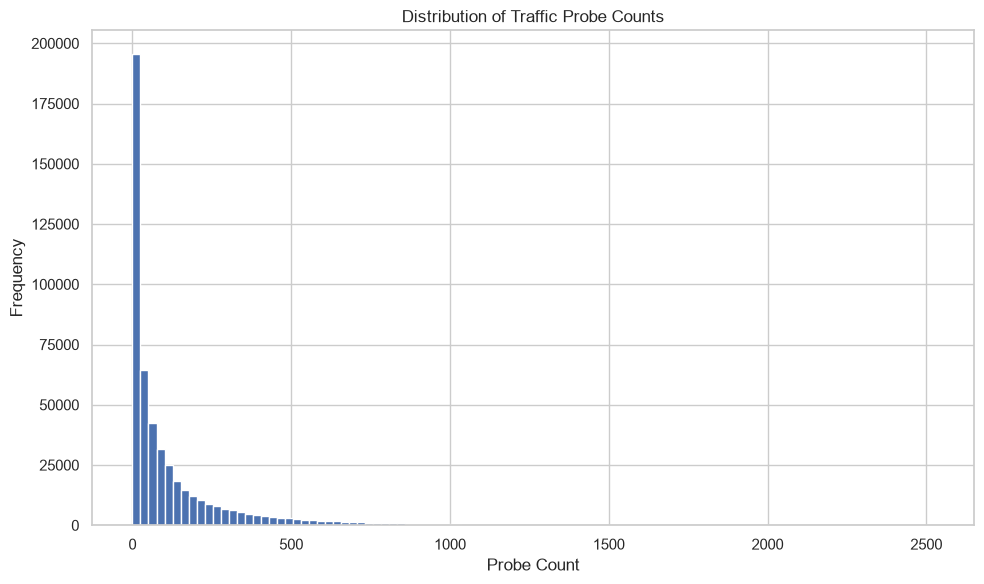

In [11]:
# 10. VISUALIZE THE PROBE COUNT DISTRIBUTION

# Select a reproducible random sample for efficient visualization.
probe_sample = traffic_model_df["probeCount"].sample(
    n=min(500_000, len(traffic_model_df)),
    random_state=42
)


# Create the histogram.
plt.figure(figsize=(10, 6))

plt.hist(
    probe_sample,
    bins=100
)

plt.title("Distribution of Traffic Probe Counts")
plt.xlabel("Probe Count")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


## 11. Average Traffic Probe Count by Hour

Traffic patterns can vary significantly throughout the day.

In this analysis, we calculate the average `probeCount` for each hour across
all road segments and dates.

This helps us identify daily traffic patterns and determine whether time of
day is an important feature for the prediction task.

Average probe count by hour:


,average_probeCount
hour,
0,74.265641
1,50.590432
2,35.976939
3,31.984514
4,37.517924
5,49.734171
6,62.591898
7,87.300493
8,124.672550


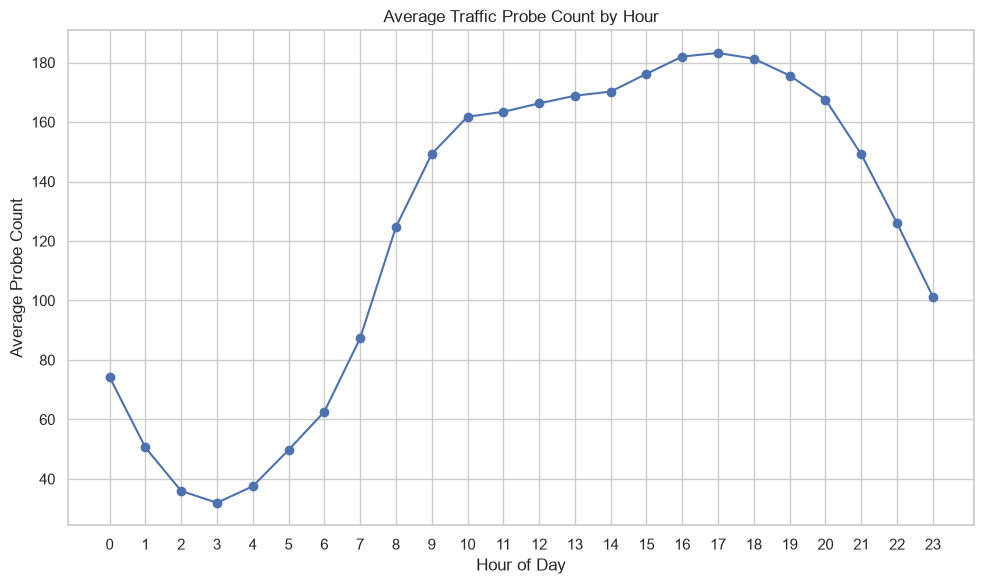

In [12]:
# 11. ANALYZE AVERAGE PROBE COUNT BY HOUR

# Calculate the average probe count for each hour of the day.
hourly_probe_count = (
    traffic_model_df
    .groupby("hour")["probeCount"]
    .mean()
)


# Display the hourly averages.
print("Average probe count by hour:")

display(
    hourly_probe_count.to_frame("average_probeCount")
)


# Create a line plot of the hourly averages.
plt.figure(figsize=(10, 6))

plt.plot(
    hourly_probe_count.index,
    hourly_probe_count.values,
    marker="o"
)

plt.title("Average Traffic Probe Count by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Probe Count")

plt.xticks(range(24))

plt.tight_layout()
plt.show()

## 12. Weekday and Weekend Traffic Comparison

Traffic patterns may differ between weekdays and weekends.

This analysis compares the average `probeCount` for weekdays and weekends
to determine whether day type is associated with different traffic activity
levels in the dataset.

Average probe count by day type:


,average_probeCount
is_weekend,
Weekday,123.837168
Weekend,124.615323


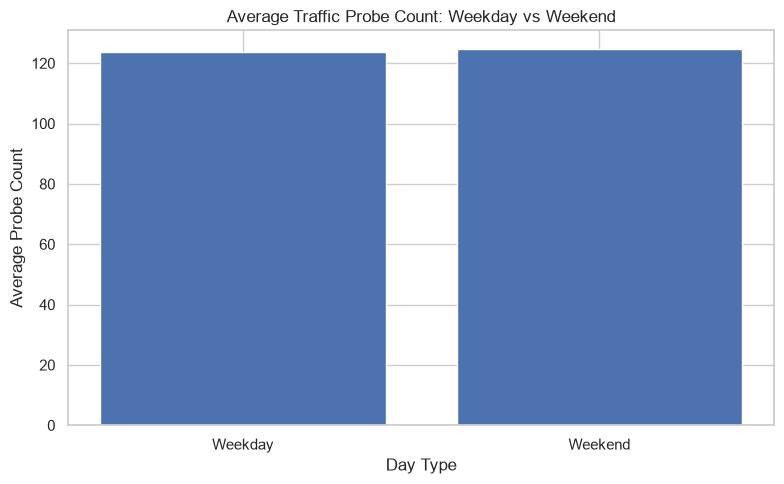

In [13]:
# 12. COMPARE WEEKDAY AND WEEKEND TRAFFIC

# Calculate the average probe count for weekdays and weekends.
weekend_comparison = (
    traffic_model_df
    .groupby("is_weekend")["probeCount"]
    .mean()
    .rename(index={
        False: "Weekday",
        True: "Weekend"
    })
)


# Display the results.
print("Average probe count by day type:")

display(
    weekend_comparison.to_frame("average_probeCount")
)


# Create a bar chart for the comparison.
plt.figure(figsize=(8, 5))

plt.bar(
    weekend_comparison.index,
    weekend_comparison.values
)

plt.title("Average Traffic Probe Count: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Probe Count")

plt.tight_layout()
plt.show()

## 13. Hourly Traffic Pattern: Weekday vs Weekend

The overall weekday and weekend averages are very similar.

To investigate whether the traffic pattern differs at particular times of
the day, we compare the average `probeCount` for each hour separately for
weekdays and weekends.

This provides a more detailed view of the relationship between day type,
time of day, and traffic activity.

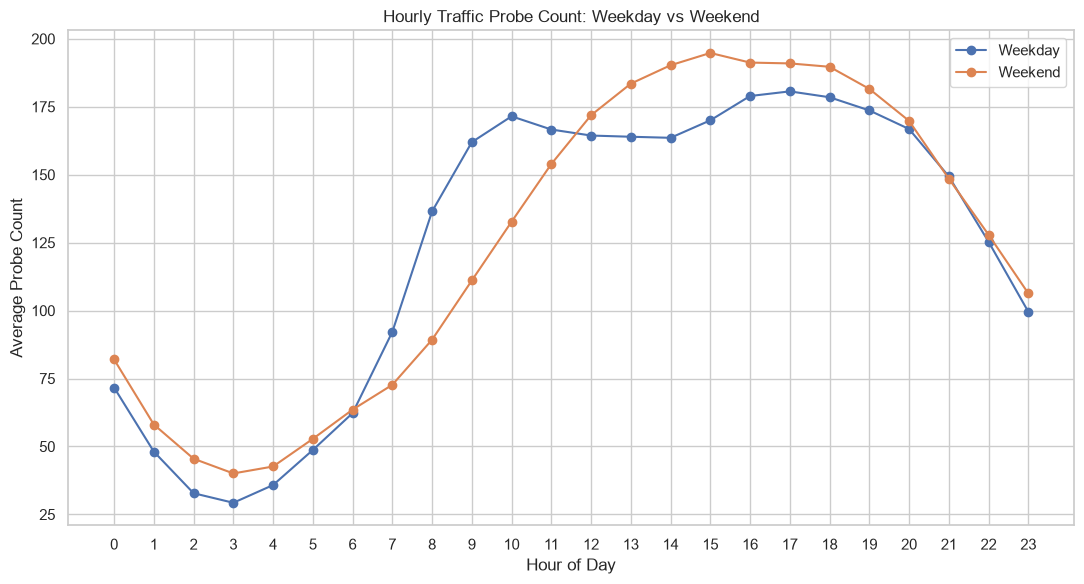

Average probe count by hour and day type:


day_type,Weekday,Weekend
hour,,
0,71.682003,82.016553
1,48.097487,58.069268
2,32.804652,45.493801
3,29.285286,40.082196
4,35.812254,42.634935
5,48.711468,52.802278
6,62.270912,63.554856
7,92.170941,72.689149
8,136.467421,89.287938


In [14]:
# 13. COMPARE HOURLY TRAFFIC PATTERNS FOR WEEKDAYS AND WEEKENDS

# Calculate the average probe count for each hour and day type.
hourly_day_type = (
    traffic_model_df
    .groupby(["hour", "is_weekend"])["probeCount"]
    .mean()
    .reset_index()
)


# Create readable labels for the two day types.
hourly_day_type["day_type"] = hourly_day_type["is_weekend"].map({
    False: "Weekday",
    True: "Weekend"
})


# Create a line plot.
plt.figure(figsize=(11, 6))

for day_type in ["Weekday", "Weekend"]:

    data = hourly_day_type[
        hourly_day_type["day_type"] == day_type
    ]

    plt.plot(
        data["hour"],
        data["probeCount"],
        marker="o",
        label=day_type
    )


plt.title("Hourly Traffic Probe Count: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Average Probe Count")

plt.xticks(range(24))
plt.legend()

plt.tight_layout()
plt.show()


# Display the numerical results as a table.
print("Average probe count by hour and day type:")

display(
    hourly_day_type[
        ["hour", "day_type", "probeCount"]
    ].pivot(
        index="hour",
        columns="day_type",
        values="probeCount"
    )
)

## 14. Road Segment Characteristics

Traffic activity can vary between different road segments because road
segments have different physical and functional characteristics.

The dataset contains variables such as speed limit, functional road
classification, and segment distance.

This section examines the unique values and basic distributions of these
road-level variables before deciding which variables should be used as
machine learning features.

In [15]:
# 14. EXAMINE ROAD SEGMENT CHARACTERISTICS

# Display the unique speed-limit values.
print("Unique speed-limit values:")

display(
    pd.Series(
        sorted(traffic_model_df["speedLimit"].unique()),
        name="speedLimit"
    )
)


# Display the unique FRC values.
print("\nUnique FRC values:")

display(
    pd.Series(
        sorted(traffic_model_df["frc"].unique()),
        name="frc"
    )
)


# Display descriptive statistics for road-level numerical variables.
print("\nRoad segment numerical summary:")

display(
    traffic_model_df[
        ["speedLimit", "frc", "distance"]
    ].describe()
)


# Count observations for each speed limit.
print("\nObservation count by speed limit:")

display(
    traffic_model_df["speedLimit"]
    .value_counts()
    .sort_index()
)


# Count observations for each FRC value.
print("\nObservation count by FRC:")

display(
    traffic_model_df["frc"]
    .value_counts()
    .sort_index()
)

Unique speed-limit values:


0     18
1     19
2     20
3     21
4     22
5     23
6     24
7     25
8     26
9     27
10    28
11    29
12    30
13    31
14    32
15    33
16    34
17    35
18    36
19    37
20    38
21    39
22    40
23    41
24    42
25    43
26    44
27    45
28    46
29    47
30    48
31    49
32    50
33    51
34    52
35    53
36    54
37    55
38    56
39    57
40    58
41    59
42    60
43    65
44    70
45    80
Name: speedLimit, dtype: int64


Unique FRC values:


0    1
1    2
2    3
3    4
4    5
5    6
Name: frc, dtype: int64


Road segment numerical summary:


,speedLimit,frc,distance
count,1.197024e+07,1.197024e+07,1.197024e+07
mean,4.752751e+01,3.609993e+00,5.629097e+01
std,8.156442e+00,1.604674e+00,6.895495e+01
min,1.800000e+01,1.000000e+00,3.500000e+00
25%,4.500000e+01,2.000000e+00,1.527000e+01
50%,5.000000e+01,4.000000e+00,3.414000e+01
75%,5.000000e+01,5.000000e+00,7.059000e+01
max,8.000000e+01,6.000000e+00,1.353770e+03



Observation count by speed limit:


speedLimit
18     196320
19      18720
20      48000
21      18240
22      15360
23      24480
24      18240
25      72960
26      17280
27      13920
28      34080
29      15360
30     144960
31      28800
32      11040
33      13920
34      13440
35      15360
36       8160
37      11040
38      14880
39       8160
40     165120
41       5280
42       9600
43       9120
44       8640
45    4422720
46      58080
47      10560
48       8640
49       8640
50    5495040
51       3360
52       3840
53       6720
54       4800
55     205440
56       5760
57       1440
58       4320
59       1920
60     391680
65       8160
70     269280
80      99360
Name: count, dtype: int64


Observation count by FRC:


frc
1    1190400
2    2310240
3    2196000
4    2941440
5     945120
6    2387040
Name: count, dtype: int64

## 15. Traffic Activity Across Road Characteristics

The dataset contains road-level characteristics such as speed limit and
functional road classification.

We compare the average `probeCount` across these values to understand whether
road characteristics are associated with different levels of traffic activity.

These comparisons are exploratory and are not used to establish causation.

Probe count by speed limit:


,speedLimit,average_probeCount,median_probeCount,observations
0,18,63.703673,10.0,196320
1,19,104.557906,42.0,18720
2,20,170.688708,88.0,48000
3,21,139.960910,69.0,18240
4,22,111.853581,42.0,15360
5,23,119.504453,44.0,24480
6,24,119.546546,50.0,18240
7,25,59.957525,10.0,72960
8,26,102.473843,45.0,17280
9,27,137.550216,58.0,13920


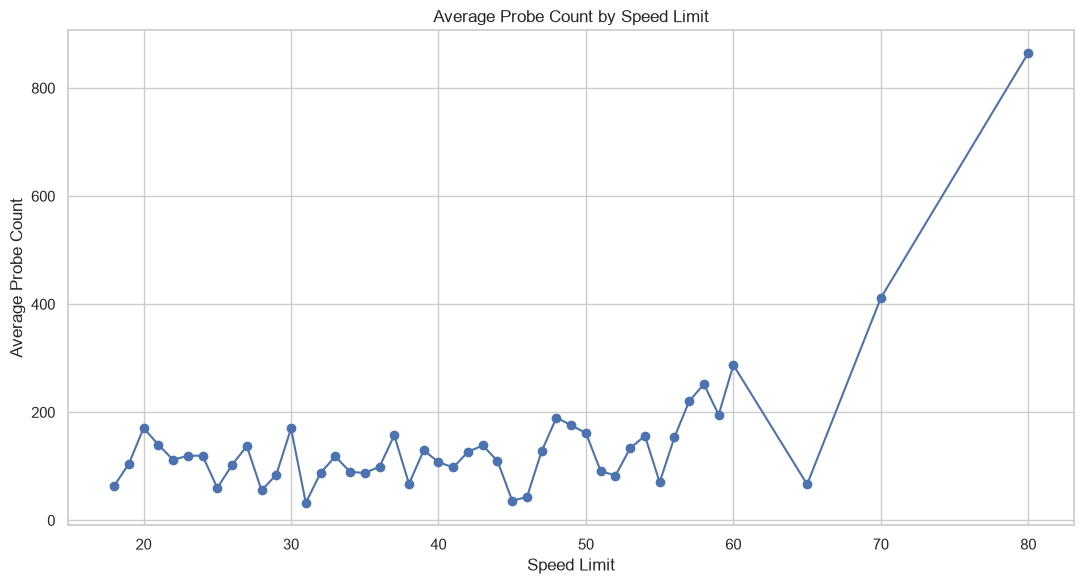

Probe count by FRC:


,frc,average_probeCount,median_probeCount,observations
0,1,415.606605,333.0,1190400
1,2,186.101426,117.0,2310240
2,3,125.549995,78.0,2196000
3,4,54.704544,27.0,2941440
4,5,41.850059,17.0,945120
5,6,35.123408,7.0,2387040


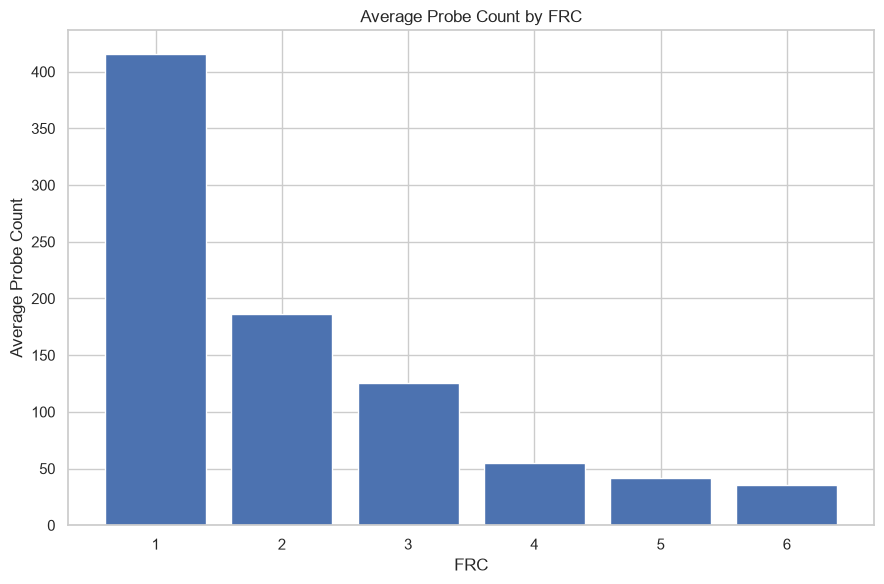

In [16]:
# 15. ANALYZE PROBE COUNT ACROSS ROAD CHARACTERISTICS

# Calculate the average probe count for each speed-limit value.
speed_limit_analysis = (
    traffic_model_df
    .groupby("speedLimit")["probeCount"]
    .agg(
        average_probeCount="mean",
        median_probeCount="median",
        observations="size"
    )
    .reset_index()
)


# Display the speed-limit analysis.
print("Probe count by speed limit:")

display(speed_limit_analysis)


# Plot the average probe count by speed limit.
plt.figure(figsize=(11, 6))

plt.plot(
    speed_limit_analysis["speedLimit"],
    speed_limit_analysis["average_probeCount"],
    marker="o"
)

plt.title("Average Probe Count by Speed Limit")
plt.xlabel("Speed Limit")
plt.ylabel("Average Probe Count")

plt.tight_layout()
plt.show()


# Calculate the average probe count for each FRC value.
frc_analysis = (
    traffic_model_df
    .groupby("frc")["probeCount"]
    .agg(
        average_probeCount="mean",
        median_probeCount="median",
        observations="size"
    )
    .reset_index()
)


# Display the FRC analysis.
print("Probe count by FRC:")

display(frc_analysis)


# Plot the average probe count by FRC.
plt.figure(figsize=(9, 6))

plt.bar(
    frc_analysis["frc"].astype(str),
    frc_analysis["average_probeCount"]
)

plt.title("Average Probe Count by FRC")
plt.xlabel("FRC")
plt.ylabel("Average Probe Count")

plt.tight_layout()
plt.show()

## 16. Consistency of Road Segment Characteristics

The variables `speedLimit`, `frc`, and `distance` describe characteristics
of individual road segments.

Because each segment appears repeatedly across different dates and hours,
we verify whether these characteristics remain constant for each segment.

If a characteristic changes within the same segment, we need to investigate
that behavior before using it as a machine learning feature.

In [17]:
# 16. CHECK CONSISTENCY OF ROAD SEGMENT CHARACTERISTICS

# Count how many different speed-limit values occur within each segment.
speed_limit_per_segment = (
    traffic_model_df
    .groupby("segmentId")["speedLimit"]
    .nunique()
)


# Count how many different FRC values occur within each segment.
frc_per_segment = (
    traffic_model_df
    .groupby("segmentId")["frc"]
    .nunique()
)


# Count how many different distance values occur within each segment.
distance_per_segment = (
    traffic_model_df
    .groupby("segmentId")["distance"]
    .nunique()
)


# Identify segments where each characteristic changes.
segments_with_multiple_speed_limits = (
    speed_limit_per_segment > 1
).sum()

segments_with_multiple_frc_values = (
    frc_per_segment > 1
).sum()

segments_with_multiple_distances = (
    distance_per_segment > 1
).sum()


# Display the results.
print("Segments with more than one speed-limit value:")
print(segments_with_multiple_speed_limits)

print("\nSegments with more than one FRC value:")
print(segments_with_multiple_frc_values)

print("\nSegments with more than one distance value:")
print(segments_with_multiple_distances)


# Display the maximum number of unique values found per segment.
print("\nMaximum number of speed-limit values for one segment:")
print(speed_limit_per_segment.max())

print("\nMaximum number of FRC values for one segment:")
print(frc_per_segment.max())

print("\nMaximum number of distance values for one segment:")
print(distance_per_segment.max())

Segments with more than one speed-limit value:
0

Segments with more than one FRC value:
0

Segments with more than one distance value:
0

Maximum number of speed-limit values for one segment:
1

Maximum number of FRC values for one segment:
1

Maximum number of distance values for one segment:
1


## 17. Inspecting Additional Dataset Sources

The ZIP archive contains additional JSON and CSV files containing aggregated
traffic information.

These files are inspected before finalizing the machine learning target and
predictor variables.

This step is important for identifying variables that may contain information
derived from the traffic measurements and could therefore introduce data
leakage into the prediction task.

In [18]:
# 17. INSPECT ADDITIONAL DATASET SOURCES

# Store the contents of the additional dataset files.
additional_files = []


# Open the original ZIP archive.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    # Select JSON and CSV files outside the daily probe-count directory.
    for file_name in zip_file.namelist():

        if file_name.endswith((".json", ".csv")):
            if "probe_counts/geojson/" not in file_name:
                additional_files.append(file_name)


# Display the files that will be inspected.
print("Additional dataset files:")
for file_name in additional_files:
    print(file_name)

Additional dataset files:
new_delhi_traffic_dataset/facility/features_geopkg.json
new_delhi_traffic_dataset/geojson/new_delhi.json
new_delhi_traffic_dataset/global_metrics/2024_city_rush_hour.json
new_delhi_traffic_dataset/global_metrics/2024_urban_rush_hour.json
new_delhi_traffic_dataset/global_metrics/new_delhi_2024_city_traffic.json
new_delhi_traffic_dataset/global_metrics/new_delhi_2024_urban_traffic.json
new_delhi_traffic_dataset/weekday_stats/2024_week_day_congestion_city.csv
new_delhi_traffic_dataset/weekday_stats/2024_week_day_congestion_urban.csv
new_delhi_traffic_dataset/weekday_stats/2024_week_day_speed_city.csv
new_delhi_traffic_dataset/weekday_stats/2024_week_day_speed_urban.csv
new_delhi_traffic_dataset/weekday_stats/2024_week_day_time_city.csv
new_delhi_traffic_dataset/weekday_stats/2024_week_day_time_urban.csv


## 17.1 Inspect Global Traffic Metrics

The dataset contains four global traffic metric files.

These files are inspected to understand what information they contain and
whether any of their variables could introduce data leakage into the
machine learning task.

In [19]:
# 17.1 INSPECT GLOBAL TRAFFIC METRICS

# List the four global metric files that we want to inspect.
global_metric_files = [
    file_name
    for file_name in additional_files
    if "global_metrics/" in file_name
]


# Open the ZIP archive and inspect each global metric file.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    for file_name in global_metric_files:

        print("\n" + "=" * 70)
        print("FILE:")
        print(file_name)
        print("=" * 70)

        # Read the JSON file from inside the ZIP archive.
        with zip_file.open(file_name) as file:
            data = json.load(file)


        # Display the top-level structure.
        print("\nTop-level data type:")
        print(type(data).__name__)


        # Display dictionary keys when the JSON contains a dictionary.
        if isinstance(data, dict):

            print("\nTop-level keys:")

            for key in data.keys():
                print("  ", key)


        # Display the number of items when the JSON contains a list.
        elif isinstance(data, list):

            print("\nNumber of items:")
            print(len(data))


        # Display a limited preview of the actual content.
        print("\nContent preview:")
        print(str(data)[:3000])


FILE:
new_delhi_traffic_dataset/global_metrics/2024_city_rush_hour.json

Top-level data type:
dict

Top-level keys:
   morning_rush_hour
   evening_rush_hour
   annual_extra_rush_hour_time

Content preview:
{'morning_rush_hour': {'time_taken_10km': '25 min 28 s', 'average_speed_kmh': 23.6, 'congestion_level_percent': 43}, 'evening_rush_hour': {'time_taken_10km': '30 min 9 s', 'average_speed_kmh': 19.9, 'congestion_level_percent': 69}, 'annual_extra_rush_hour_time': {'total': '76 hours (3 days, 4 hours)', 'difference_vs_2023': '+3 h 21 min'}}

FILE:
new_delhi_traffic_dataset/global_metrics/2024_urban_rush_hour.json

Top-level data type:
dict

Top-level keys:
   morning_rush_hour
   evening_rush_hour
   annual_extra_rush_hour_time

Content preview:
{'morning_rush_hour': {'time_taken_10km': '25 min', 'average_speed_kmh': 24.0, 'congestion_level_percent': 38}, 'evening_rush_hour': {'time_taken_10km': '29 min 47 s', 'average_speed_kmh': 20.1, 'congestion_level_percent': 63}, 'annual_extra_

## 17.2 Inspect the Remaining Global Traffic Files

In [20]:
# 17.2 INSPECT THE REMAINING GLOBAL TRAFFIC FILES

# Select the two remaining global traffic metric files.
remaining_global_files = [
    file_name
    for file_name in additional_files
    if "global_metrics/new_delhi_2024_" in file_name
]


# Open the ZIP archive.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    for file_name in remaining_global_files:

        print("\n" + "=" * 70)
        print("FILE:")
        print(file_name)
        print("=" * 70)

        # Read the JSON file.
        with zip_file.open(file_name) as file:
            data = json.load(file)

        # Show the top-level structure.
        print("\nTop-level data type:")
        print(type(data).__name__)

        # Show dictionary keys.
        if isinstance(data, dict):

            print("\nTop-level keys:")

            for key in data.keys():
                print("  ", key)

        # Show list length if applicable.
        elif isinstance(data, list):

            print("\nNumber of items:")
            print(len(data))

        # Show a limited content preview.
        print("\nContent preview:")
        print(str(data)[:3000])


FILE:
new_delhi_traffic_dataset/global_metrics/new_delhi_2024_city_traffic.json

Top-level data type:
dict

Top-level keys:
   average_travel_time_per_10_km
   difference_vs_2023_for_travel_time_per_10_km
   congestion_level
   average_congestion_level_percent
   difference_vs_2023_for_congestion_level_percent
   average_speed_km_h
   difference_vs_2023_for_speed_km_h
   worst_day_to_travel_2024
   monthly_congestion_level

Content preview:
{'average_travel_time_per_10_km': '23 min 24 s', 'difference_vs_2023_for_travel_time_per_10_km': '+10 s', 'congestion_level': 147, 'average_congestion_level_percent': 33, 'difference_vs_2023_for_congestion_level_percent': '+1%p', 'average_speed_km_h': 25.6, 'difference_vs_2023_for_speed_km_h': '-0.2 km/h', 'worst_day_to_travel_2024': {'date': 'October 25, Friday', 'avg_travel_time_per_10_km': '27 min 51 s', 'congestion_level_percent': 57}, 'monthly_congestion_level': [{'month': 'Jan', '2024': 34, '2023': 33}, {'month': 'Feb', '2024': 34, '2023': 33

## 17.3 Inspect Weekday Statistics

The dataset contains six weekday-statistics CSV files related to congestion,
speed, and travel time.

These files are inspected to determine their structure, time coverage, and
relationship to the main road-segment probe-count data.

They will not be used as machine learning features until their role and
possible leakage have been verified.

In [21]:
# 17.3 INSPECT WEEKDAY STATISTICS

# Select the six weekday-statistics files.
weekday_stat_files = [
    file_name
    for file_name in additional_files
    if "weekday_stats/" in file_name
]


# Open the ZIP archive.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    for file_name in weekday_stat_files:

        print("\n" + "=" * 70)
        print("FILE:")
        print(file_name)
        print("=" * 70)

        # Read the CSV file directly from the ZIP archive.
        with zip_file.open(file_name) as file:
            data = pd.read_csv(file)

        # Display basic information about the file.
        print("\nShape:")
        print(data.shape)

        print("\nColumns:")
        print(list(data.columns))

        print("\nData types:")
        print(data.dtypes)

        print("\nFirst 5 rows:")
        display(data.head())


FILE:
new_delhi_traffic_dataset/weekday_stats/2024_week_day_congestion_city.csv

Shape:
(12, 8)

Columns:
['Time', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

Data types:
Time         str
Sunday       str
Monday       str
Tuesday      str
Wednesday    str
Thursday     str
Friday       str
Saturday     str
dtype: object

First 5 rows:


,Time,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday
0,12:00 AM,0%,0%,0%,0%,0%,0%,0%
1,02:00 AM,0%,0%,0%,0%,0%,0%,0%
2,04:00 AM,0%,0%,0%,0%,0%,0%,0%
3,06:00 AM,0%,0%,0%,0%,0%,0%,0%
4,08:00 AM,0%,11%,11%,10%,9%,0%,0%



FILE:
new_delhi_traffic_dataset/weekday_stats/2024_week_day_congestion_urban.csv

Shape:
(12, 8)

Columns:
['Time', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

Data types:
Time         str
Sunday       str
Monday       str
Tuesday      str
Wednesday    str
Thursday     str
Friday       str
Saturday     str
dtype: object

First 5 rows:


,Time,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday
0,12:00 AM,0%,0%,0%,0%,0%,0%,0%
1,02:00 AM,0%,0%,0%,0%,0%,0%,0%
2,04:00 AM,0%,0%,0%,0%,0%,0%,0%
3,06:00 AM,0%,0%,0%,0%,0%,0%,0%
4,08:00 AM,0%,12%,12%,12%,11%,0%,2%



FILE:
new_delhi_traffic_dataset/weekday_stats/2024_week_day_speed_city.csv

Shape:
(12, 8)

Columns:
['Time', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

Data types:
Time         str
Sunday       str
Monday       str
Tuesday      str
Wednesday    str
Thursday     str
Friday       str
Saturday     str
dtype: object

First 5 rows:


,Time,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday
0,12:00 AM,35 km/h,37 km/h,36 km/h,36 km/h,36 km/h,36 km/h,36 km/h
1,02:00 AM,37 km/h,39 km/h,38 km/h,37 km/h,38 km/h,38 km/h,38 km/h
2,04:00 AM,39 km/h,40 km/h,39 km/h,39 km/h,39 km/h,39 km/h,39 km/h
3,06:00 AM,36 km/h,41 km/h,37 km/h,35 km/h,35 km/h,35 km/h,35 km/h
4,08:00 AM,34 km/h,28 km/h,27 km/h,28 km/h,28 km/h,28 km/h,31 km/h


... (2 outputs left out)


FILE:
new_delhi_traffic_dataset/weekday_stats/2024_week_day_time_city.csv

Shape:
(12, 8)

Columns:
['Time', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

Data types:
Time         str
Sunday       str
Monday       str
Tuesday      str
Wednesday    str
Thursday     str
Friday       str
Saturday     str
dtype: object

First 5 rows:


,Time,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday
0,12:00 AM,17 min 11 s,16 min 2 s,16 min 29 s,16 min 40 s,16 min 41 s,16 min 42 s,16 min 50 s
1,02:00 AM,16 min 13 s,15 min 30 s,15 min 54 s,15 min 27 s,15 min 19 s,16 min,15 min 58 s
2,04:00 AM,15 min 30 s,14 min 58 s,15 min 18 s,15 min 15 s,15 min 8 s,15 min 29 s,15 min 19 s
3,06:00 AM,15 min 9 s,14 min 38 s,15 min 3 s,15 min 1 s,15 min 40 s,16 min 6 s,15 min 49 s
4,08:00 AM,16 min 19 s,16 min 5 s,16 min 32 s,16 min 57 s,16 min 48 s,17 min 25 s,17 min 9 s



FILE:
new_delhi_traffic_dataset/weekday_stats/2024_week_day_time_urban.csv

Shape:
(12, 8)

Columns:
['Time', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

Data types:
Time         str
Sunday       str
Monday       str
Tuesday      str
Wednesday    str
Thursday     str
Friday       str
Saturday     str
dtype: object

First 5 rows:


,Time,Sunday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday
0,12:00 AM,17 min 3 s,16 min 15 s,16 min 47 s,16 min 51 s,16 min 56 s,16 min 51 s,17 min
1,02:00 AM,16 min 10 s,15 min 44 s,15 min 21 s,15 min 39 s,15 min 11 s,15 min 44 s,15 min 33 s
2,04:00 AM,15 min 39 s,15 min 21 s,15 min 39 s,15 min 42 s,15 min 36 s,15 min 39 s,15 min 26 s
3,06:00 AM,15 min 24 s,15 min 10 s,15 min 35 s,15 min 54 s,15 min 48 s,15 min 55 s,15 min 37 s
4,08:00 AM,16 min 25 s,16 min 53 s,17 min 29 s,17 min 38 s,17 min 30 s,17 min 41 s,17 min 2 s


## 17.4 Read Dataset Documentation

The dataset README is examined to understand the meaning of the main
variables and the source's description of the probe-count data.

This documentation will be used before finalizing the machine learning
target and feature definitions.

In [22]:
# 17.4 READ THE DATASET README

# Open the ZIP archive and read the dataset README file.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    with zip_file.open(
        "new_delhi_traffic_dataset/README.md"
    ) as file:

        readme_text = file.read().decode("utf-8")


# Display the README content.
print(readme_text)

# 🛣️ New Delhi Traffic Probe Count & Analytics Dataset (2024)

**Created by: Ryan Madhuwala (RAW), Founder of Garudex Labs**

## 📦 Overview

This dataset is a comprehensive, large-scale traffic analysis and urban infrastructure resource capturing **probe count data** and **urban metrics** across **New Delhi** and surrounding regions, featuring a **15,000+ km road network**.

It includes both **generalized annual traffic analytics for 2024** and **detailed probe count data from August 11–30, 2024**, a period rich in cultural and traffic variation due to Indian national festivals like **Independence Day, Rakshabandhan, and Janmashtami**, alongside the **monsoon season** — making this an invaluable dataset for mobility research, urban planning, AI traffic forecasting, smart city infrastructure, and congestion pattern modeling.

---

## 📁 Folder Structure

```bash
new_delhi_traffic_dataset/
│
├── facility/                  # Category-wise infrastructure features (education, healthcare, tra

## 18. Inspecting a Raw Road-Segment Record

The original GeoJSON structure is inspected using one road-segment feature.
This helps verify the structure of the raw data before and after the
flattening process used to create the main tabular dataset.

In [23]:
# 18. Inspecting a Raw Road-Segment Record

# Open the first daily GeoJSON file.
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    # Get the first probe-count GeoJSON file.
    probe_files = sorted([
        name
        for name in zip_file.namelist()
        if name.startswith("new_delhi_traffic_dataset/probe_counts/geojson/")
        and name.endswith(".geojson")
    ])

    first_probe_file = probe_files[0]

    # Read the GeoJSON file.
    with zip_file.open(first_probe_file) as file:
        first_geojson = json.load(file)


# Find the first actual road-segment feature.
road_feature = None

for feature in first_geojson["features"]:
    properties = feature.get("properties", {})

    if "segmentId" in properties:
        road_feature = feature
        break


# Display the complete properties of one road segment.
print("File:")
print(first_probe_file)

print("\nOne raw road-segment record:")
print(json.dumps(
    road_feature["properties"],
    indent=4
))

File:
new_delhi_traffic_dataset/probe_counts/geojson/new_delhi__2024-08-11_to_2024-08-11_.geojson

One raw road-segment record:
{
    "segmentId": -13560111507837,
    "newSegmentId": "-00004e30-3400-0400-0000-0000008bad86",
    "speedLimit": 45,
    "frc": 6,
    "streetName": "Ghata Masjid Road",
    "distance": 20.87,
    "segmentProbeCounts": [
        {
            "timeSet": 2,
            "dateRange": 1,
            "probeCount": 4
        },
        {
            "timeSet": 3,
            "dateRange": 1,
            "probeCount": 2
        },
        {
            "timeSet": 4,
            "dateRange": 1,
            "probeCount": 1
        },
        {
            "timeSet": 5,
            "dateRange": 1,
            "probeCount": 0
        },
        {
            "timeSet": 6,
            "dateRange": 1,
            "probeCount": 0
        },
        {
            "timeSet": 7,
            "dateRange": 1,
            "probeCount": 0
        },
        {
            "timeSet"

## 19. Probe-Count Variation Within Road Segments

The variation of `probeCount` within individual road segments is examined
to determine whether probe-count activity changes over time.

This is relevant to the prediction problem because a useful forecasting
target should contain temporal variation rather than remain constant for
each road segment.

In [24]:
# 19. Probe-Count Variation Within Road Segments

# Group all hourly observations by road segment.
segment_probe_stats = traffic_df.groupby("segmentId")["probeCount"].agg(
    segment_mean="mean",
    segment_std="std",
    segment_min="min",
    segment_max="max"
)

# Count segments where probe count never changes across the 480 observations.
constant_segments = (
    segment_probe_stats["segment_std"].fillna(0) == 0
).sum()

# Get the total number of unique road segments.
total_segments = segment_probe_stats.shape[0]

# Calculate the percentage of segments with constant probe count.
constant_percentage = (
    constant_segments / total_segments * 100
)

# Display the main results.
print("Total road segments:", total_segments)
print("Segments with constant probe count:", constant_segments)
print(
    "Percentage of segments with constant probe count:",
    round(constant_percentage, 2),
    "%"
)

# Display the distribution of within-segment standard deviation.
print("\nWithin-segment probe-count standard deviation:")
print(segment_probe_stats["segment_std"].describe())

Total road segments: 24938
Segments with constant probe count: 185
Percentage of segments with constant probe count: 0.74 %

Within-segment probe-count standard deviation:
count    24938.000000
mean        67.165985
std         79.553036
min          0.000000
25%         11.911117
50%         38.038208
75%         92.333652
max        598.675236
Name: segment_std, dtype: float64


# 20. DEFINE THE PREDICTION PROBLEM

The objective of this project is to predict the traffic probe count for a road
segment in the next hour using information that would have been available up
to the current hour.

For example, observations available at 10:00 can be used to predict the probe
count at 11:00 for the same road segment.

The prediction target will therefore be the next-hour `probeCount`.

This formulation converts the dataset from a descriptive traffic-analysis
dataset into a time-aware forecasting problem.

The target variable is not treated as a direct measurement of congestion.
Instead, the predicted probe count represents future traffic probe activity,
which can later be used to construct a project-defined traffic-load or
congestion proxy if required.

To avoid data leakage, features used for prediction must contain only
information available at or before the prediction time. Future observations
must not be used to construct predictor variables.

In [25]:
# 20. VERIFY THE VARIABLES THAT WILL BE USED FOR THE PREDICTION PROBLEM

# The prediction problem will use the engineered dataset because
# it contains the datetime feature created in Section 7.

prediction_columns = [
    "segmentId",
    "datetime",
    "probeCount"
]

print("Columns used to define the prediction problem:")
print(prediction_columns)

print("\nCurrent modeling dataset shape:")
print(traffic_model_df.shape)

print("\nPreview of the prediction-related columns:")
display(
    traffic_model_df[prediction_columns].head()
)

print("\nData types:")
print(
    traffic_model_df[prediction_columns].dtypes
)

Columns used to define the prediction problem:
['segmentId', 'datetime', 'probeCount']

Current modeling dataset shape:
(11970240, 15)

Preview of the prediction-related columns:


,segmentId,datetime,probeCount
0,-13560111507837,2024-08-11 00:00:00,4
1,-13560111507837,2024-08-11 01:00:00,2
2,-13560111507837,2024-08-11 02:00:00,1
3,-13560111507837,2024-08-11 03:00:00,0
4,-13560111507837,2024-08-11 04:00:00,0



Data types:
segmentId              int64
datetime      datetime64[us]
probeCount             int64
dtype: object


# 21. VERIFY TEMPORAL STRUCTURE BEFORE TARGET CONSTRUCTION

Before creating the next-hour prediction target, the temporal ordering of the
observations is verified for each road segment.

A valid next-hour target requires consecutive hourly observations for the same
segment. This check helps ensure that a value from one observation is shifted
to the correct following hour rather than being incorrectly paired with a
non-consecutive observation.

In [26]:
# 21. VERIFY THE TEMPORAL STRUCTURE BEFORE CREATING THE NEXT-HOUR TARGET

# Sort the modeling dataset by road segment and timestamp.
# This ensures that observations within each segment are in chronological order.
traffic_model_df = traffic_model_df.sort_values(
    by=["segmentId", "datetime"]
).reset_index(drop=True)


# Calculate the time difference between consecutive observations
# within each road segment.
traffic_model_df["time_difference"] = (
    traffic_model_df
    .groupby("segmentId")["datetime"]
    .diff()
)


# Count observations where the time difference is not exactly one hour.
# The first observation of each segment has no previous observation,
# so it is excluded from this check.
non_hourly_gaps = (
    traffic_model_df["time_difference"].notna()
    & (
        traffic_model_df["time_difference"]
        != pd.Timedelta(hours=1)
    )
).sum()


print(
    "Number of non-hourly gaps within road segments:",
    non_hourly_gaps
)


# Count how many observations are available for each road segment.
observations_per_segment = (
    traffic_model_df
    .groupby("segmentId")
    .size()
)


print(
    "\nMinimum observations per segment:",
    observations_per_segment.min()
)

print(
    "Maximum observations per segment:",
    observations_per_segment.max()
)

print(
    "Expected observations per segment: 480"
)

# Remove the temporary temporal-verification column.
# It was used only to verify hourly continuity and is not a model feature.
traffic_model_df = traffic_model_df.drop(
    columns=["time_difference"]
)

Number of non-hourly gaps within road segments: 0

Minimum observations per segment: 480
Maximum observations per segment: 480
Expected observations per segment: 480


# 22. CREATE THE NEXT-HOUR PREDICTION TARGET

The prediction target is defined as the `probeCount` observed during the next
hour for the same road segment.

For each observation at time t, the target represents the probe count at
time t+1 for the same `segmentId`.

The target is created by shifting `probeCount` by one observation within each
road segment after the data has been sorted chronologically.

The temporal verification in the previous section confirmed that each segment
contains consecutive hourly observations, so the one-step shift corresponds
to the next hour.

The current-hour `probeCount` is retained as an input variable for later
feature engineering, while the shifted value becomes the prediction target.

The final observation of each road segment has no next-hour observation and
therefore receives a missing target. Such rows will be removed from the
modeling dataset after the target construction is verified.

In [27]:
# 22. CREATE THE NEXT-HOUR PREDICTION TARGET

# Create the target by shifting probeCount forward by one observation
# within each road segment.
#
# Because the data was sorted by segmentId and datetime in Section 21,
# the shifted value represents the probe count in the next hour for
# the same road segment.
traffic_model_df["target_next_hour_probeCount"] = (
    traffic_model_df
    .groupby("segmentId")["probeCount"]
    .shift(-1)
)


# Display a few observations so that we can manually verify
# the relationship between the current probe count and the target.
target_check_columns = [
    "segmentId",
    "datetime",
    "probeCount",
    "target_next_hour_probeCount"
]

print("Preview of the current probe count and next-hour target:")

display(
    traffic_model_df[target_check_columns].head(10)
)


# Count the missing target values.
# Each road segment should have exactly one missing target:
# its final observation has no following hour in the dataset.
missing_targets = (
    traffic_model_df["target_next_hour_probeCount"]
    .isna()
    .sum()
)

print(
    "\nNumber of observations without a next-hour target:",
    missing_targets
)


# Verify the expected number of missing targets.
number_of_segments = traffic_model_df["segmentId"].nunique()

print(
    "Number of road segments:",
    number_of_segments
)

print(
    "Expected number of missing targets:",
    number_of_segments
)

Preview of the current probe count and next-hour target:


,segmentId,datetime,probeCount,target_next_hour_probeCount
0,-13560345653226,2024-08-11 00:00:00,0,1.0
1,-13560345653226,2024-08-11 01:00:00,1,0.0
2,-13560345653226,2024-08-11 02:00:00,0,0.0
3,-13560345653226,2024-08-11 03:00:00,0,0.0
4,-13560345653226,2024-08-11 04:00:00,0,0.0
5,-13560345653226,2024-08-11 05:00:00,0,0.0
6,-13560345653226,2024-08-11 06:00:00,0,0.0
7,-13560345653226,2024-08-11 07:00:00,0,0.0
8,-13560345653226,2024-08-11 08:00:00,0,0.0
9,-13560345653226,2024-08-11 09:00:00,0,0.0



Number of observations without a next-hour target: 24938
Number of road segments: 24938
Expected number of missing targets: 24938


# 23. VERIFY THE NEXT-HOUR TARGET

The newly created target variable is validated by comparing each observation's
timestamp with the timestamp of the observation used to construct its target.

For every observation with a non-missing target, the corresponding target
observation should occur exactly one hour later for the same road segment.

This verification ensures that the target represents the intended next-hour
probe count and that the target construction did not introduce an unintended
temporal shift.

In [28]:
# 23. VERIFY THE NEXT-HOUR TARGET

# Create the timestamp of the next observation within each road segment.
# This is used only for validation and will not be used as a model feature.
traffic_model_df["next_datetime_check"] = (
    traffic_model_df
    .groupby("segmentId")["datetime"]
    .shift(-1)
)


# Calculate the time difference between the current observation
# and the observation whose probeCount was assigned as the target.
target_time_difference = (
    traffic_model_df["next_datetime_check"]
    - traffic_model_df["datetime"]
)


# Check only observations that have a valid next-hour target.
valid_target_rows = (
    traffic_model_df["target_next_hour_probeCount"].notna()
)


# Count observations where the target observation is not exactly
# one hour after the current observation.
invalid_target_intervals = (
    valid_target_rows
    & (
        target_time_difference
        != pd.Timedelta(hours=1)
    )
).sum()


print(
    "Number of observations with an invalid target time interval:",
    invalid_target_intervals
)


# Display a small sample showing the current timestamp,
# next timestamp, current probe count, and target probe count.
target_validation_columns = [
    "segmentId",
    "datetime",
    "next_datetime_check",
    "probeCount",
    "target_next_hour_probeCount"
]

print("\nTarget-time validation preview:")

display(
    traffic_model_df[target_validation_columns].head(10)
)
# Remove the temporary timestamp column used only for target validation.
# It is not part of the prediction features.
traffic_model_df = traffic_model_df.drop(
    columns=["next_datetime_check"]
)

Number of observations with an invalid target time interval: 0

Target-time validation preview:


,segmentId,datetime,next_datetime_check,probeCount,target_next_hour_probeCount
0,-13560345653226,2024-08-11 00:00:00,2024-08-11 01:00:00,0,1.0
1,-13560345653226,2024-08-11 01:00:00,2024-08-11 02:00:00,1,0.0
2,-13560345653226,2024-08-11 02:00:00,2024-08-11 03:00:00,0,0.0
3,-13560345653226,2024-08-11 03:00:00,2024-08-11 04:00:00,0,0.0
4,-13560345653226,2024-08-11 04:00:00,2024-08-11 05:00:00,0,0.0
5,-13560345653226,2024-08-11 05:00:00,2024-08-11 06:00:00,0,0.0
6,-13560345653226,2024-08-11 06:00:00,2024-08-11 07:00:00,0,0.0
7,-13560345653226,2024-08-11 07:00:00,2024-08-11 08:00:00,0,0.0
8,-13560345653226,2024-08-11 08:00:00,2024-08-11 09:00:00,0,0.0
9,-13560345653226,2024-08-11 09:00:00,2024-08-11 10:00:00,0,0.0


# 24. CREATE THE FINAL MODELING DATASET

The final observation of each road segment does not have a corresponding
next-hour observation within the available dataset. Therefore, these
observations cannot be used for supervised learning with the next-hour
prediction target.

These rows are removed from the modeling dataset.

The resulting dataset contains only observations for which the next-hour
`probeCount` target is available.

In [29]:
# 24. CREATE THE FINAL MODELING DATASET

# Count the observations before removing rows with a missing target.
rows_before = len(traffic_model_df)

print("Rows before removing missing targets:", rows_before)


# Remove observations where the next-hour target is missing.
# These are the final observations of each road segment.
traffic_model_df = traffic_model_df.dropna(
    subset=["target_next_hour_probeCount"]
).copy()


# Reset the DataFrame index after removing rows.
traffic_model_df = traffic_model_df.reset_index(drop=True)


# Count the observations after removing rows with a missing target.
rows_after = len(traffic_model_df)

print("Rows after removing missing targets:", rows_after)

print(
    "Rows removed:",
    rows_before - rows_after
)


# Verify that no missing target values remain.
remaining_missing_targets = (
    traffic_model_df["target_next_hour_probeCount"]
    .isna()
    .sum()
)

print(
    "Remaining missing target values:",
    remaining_missing_targets
)

Rows before removing missing targets: 11970240
Rows after removing missing targets: 11945302
Rows removed: 24938
Remaining missing target values: 0


# 25. CREATE LEAKAGE-SAFE HISTORICAL FEATURES

Historical probe-count features are created to provide the machine learning
models with information about recent traffic activity for each road segment.

The lag features represent probe counts observed before the prediction time:

- `probeCount_lag_1` represents the probe count one hour earlier.
- `probeCount_lag_2` represents the probe count two hours earlier.
- `probeCount_lag_3` represents the probe count three hours earlier.
- `probeCount_lag_24` represents the probe count 24 hours earlier.

These features are calculated separately for each road segment so that traffic
information from one road segment is never used as a historical feature for
another segment.

Only past observations are used to construct these predictors. The
next-hour target is not used in feature construction, which helps prevent
target leakage.

In [30]:
# 25. CREATE LEAKAGE-SAFE HISTORICAL FEATURES

# Create lagged probe-count features separately for each road segment.
# The dataset is already sorted chronologically within each segment.
traffic_model_df["probeCount_lag_1"] = (
    traffic_model_df
    .groupby("segmentId")["probeCount"]
    .shift(1)
)

traffic_model_df["probeCount_lag_2"] = (
    traffic_model_df
    .groupby("segmentId")["probeCount"]
    .shift(2)
)

traffic_model_df["probeCount_lag_3"] = (
    traffic_model_df
    .groupby("segmentId")["probeCount"]
    .shift(3)
)

traffic_model_df["probeCount_lag_24"] = (
    traffic_model_df
    .groupby("segmentId")["probeCount"]
    .shift(24)
)


# Display the newly created historical features.
lag_columns = [
    "segmentId",
    "datetime",
    "probeCount",
    "probeCount_lag_1",
    "probeCount_lag_2",
    "probeCount_lag_3",
    "probeCount_lag_24",
    "target_next_hour_probeCount"
]

display(
    traffic_model_df[lag_columns].head(30)
)

,segmentId,datetime,probeCount,probeCount_lag_1,probeCount_lag_2,probeCount_lag_3,probeCount_lag_24,target_next_hour_probeCount
0,-13560345653226,2024-08-11 00:00:00,0,NaN,NaN,NaN,NaN,1.0
1,-13560345653226,2024-08-11 01:00:00,1,0.0,NaN,NaN,NaN,0.0
2,-13560345653226,2024-08-11 02:00:00,0,1.0,0.0,NaN,NaN,0.0
3,-13560345653226,2024-08-11 03:00:00,0,0.0,1.0,0.0,NaN,0.0
4,-13560345653226,2024-08-11 04:00:00,0,0.0,0.0,1.0,NaN,0.0
5,-13560345653226,2024-08-11 05:00:00,0,0.0,0.0,0.0,NaN,0.0
6,-13560345653226,2024-08-11 06:00:00,0,0.0,0.0,0.0,NaN,0.0
7,-13560345653226,2024-08-11 07:00:00,0,0.0,0.0,0.0,NaN,0.0
8,-13560345653226,2024-08-11 08:00:00,0,0.0,0.0,0.0,NaN,0.0
9,-13560345653226,2024-08-11 09:00:00,0,0.0,0.0,0.0,NaN,0.0


# 26. CHECK MISSING VALUES IN HISTORICAL FEATURES

Lagged features require previous observations to be available for the same
road segment. Therefore, missing values occur naturally at the beginning of
each segment's time series.

The number of missing values in each lag feature is examined before deciding
how these observations should be handled.

These missing values are not interpreted as zero traffic, because a missing
historical observation and a measured probe count of zero represent different
conditions.

In [31]:
# 26. CHECK MISSING VALUES IN HISTORICAL FEATURES

# List the historical lag features created in Section 25.
lag_features = [
    "probeCount_lag_1",
    "probeCount_lag_2",
    "probeCount_lag_3",
    "probeCount_lag_24"
]


# Count the missing values in each lag feature.
missing_lag_values = (
    traffic_model_df[lag_features]
    .isna()
    .sum()
)


print("Missing values in historical lag features:")
print(missing_lag_values)


# Calculate the percentage of observations affected by missing values
# in each lag feature.
missing_lag_percentage = (
    traffic_model_df[lag_features]
    .isna()
    .mean()
    * 100
)


print("\nPercentage of observations with missing lag values:")
print(missing_lag_percentage)

Missing values in historical lag features:
probeCount_lag_1      24938
probeCount_lag_2      49876
probeCount_lag_3      74814
probeCount_lag_24    598512
dtype: int64

Percentage of observations with missing lag values:
probeCount_lag_1     0.208768
probeCount_lag_2     0.417537
probeCount_lag_3     0.626305
probeCount_lag_24    5.010438
dtype: float64


# 27. CREATE THE HISTORICAL-FEATURE MODELING DATASET

The first 24 observations of each road segment do not have sufficient
historical information to calculate the 24-hour lag feature.

These observations are excluded rather than imputed because a missing
historical observation does not represent a measured probe count of zero.

After this step, every remaining observation has valid values for all four
historical lag features and the next-hour prediction target.

In [32]:
# 27. CREATE THE HISTORICAL-FEATURE MODELING DATASET

# Store the number of observations before removing rows with
# incomplete historical lag information.
rows_before_lag_filter = len(traffic_model_df)

print(
    "Rows before removing incomplete lag histories:",
    rows_before_lag_filter
)


# Remove observations where any of the required historical lag features
# is missing.
#
# Since lag_24 is the longest lag, this removes the first 24 observations
# from each road segment.
traffic_model_df = traffic_model_df.dropna(
    subset=lag_features
).copy()


# Reset the index after removing the initial observations.
traffic_model_df = traffic_model_df.reset_index(drop=True)


# Store the number of observations after the filtering step.
rows_after_lag_filter = len(traffic_model_df)

print(
    "Rows after removing incomplete lag histories:",
    rows_after_lag_filter
)

print(
    "Rows removed:",
    rows_before_lag_filter - rows_after_lag_filter
)


# Verify that no missing values remain in the required lag features.
remaining_missing_lags = (
    traffic_model_df[lag_features]
    .isna()
    .sum()
)

print("\nRemaining missing values in historical lag features:")
print(remaining_missing_lags)

Rows before removing incomplete lag histories: 11945302
Rows after removing incomplete lag histories: 11346790
Rows removed: 598512

Remaining missing values in historical lag features:
probeCount_lag_1     0
probeCount_lag_2     0
probeCount_lag_3     0
probeCount_lag_24    0
dtype: int64


# 28. CREATE CYCLICAL TIME FEATURES

Traffic patterns can vary systematically with the time of day and day of the
week.

Because hours and days of the week are cyclical variables, their numerical
values are transformed using sine and cosine functions.

For the hour of day, the transformation represents the 24-hour cycle.

For the day of the week, the transformation represents the 7-day cycle.

These features provide the regression models with a continuous representation
of temporal position while preserving the cyclical relationship between the
beginning and end of each cycle.

In [33]:
# 28. CREATE CYCLICAL TIME FEATURES

# Represent the hour of day as a position on a 24-hour cycle.
traffic_model_df["hour_sin"] = np.sin(
    2 * np.pi * traffic_model_df["hour"] / 24
)

traffic_model_df["hour_cos"] = np.cos(
    2 * np.pi * traffic_model_df["hour"] / 24
)


# Represent the day of the week as a position on a 7-day cycle.
# day_of_week uses Monday=0 through Sunday=6.
traffic_model_df["day_of_week_sin"] = np.sin(
    2 * np.pi * traffic_model_df["day_of_week"] / 7
)

traffic_model_df["day_of_week_cos"] = np.cos(
    2 * np.pi * traffic_model_df["day_of_week"] / 7
)


# Display the original temporal variables together with
# their newly created cyclical representations.
time_feature_columns = [
    "datetime",
    "hour",
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "day_of_week_sin",
    "day_of_week_cos"
]

display(
    traffic_model_df[time_feature_columns].head(10)
)

,datetime,hour,day_of_week,is_weekend,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos
0,2024-08-12 00:00:00,0,0,False,0.000000,1.000000e+00,0.0,1.0
1,2024-08-12 01:00:00,1,0,False,0.258819,9.659258e-01,0.0,1.0
2,2024-08-12 02:00:00,2,0,False,0.500000,8.660254e-01,0.0,1.0
3,2024-08-12 03:00:00,3,0,False,0.707107,7.071068e-01,0.0,1.0
4,2024-08-12 04:00:00,4,0,False,0.866025,5.000000e-01,0.0,1.0
5,2024-08-12 05:00:00,5,0,False,0.965926,2.588190e-01,0.0,1.0
6,2024-08-12 06:00:00,6,0,False,1.000000,6.123234e-17,0.0,1.0
7,2024-08-12 07:00:00,7,0,False,0.965926,-2.588190e-01,0.0,1.0
8,2024-08-12 08:00:00,8,0,False,0.866025,-5.000000e-01,0.0,1.0
9,2024-08-12 09:00:00,9,0,False,0.707107,-7.071068e-01,0.0,1.0


# 29. CREATE LEAKAGE-SAFE ROLLING TRAFFIC FEATURES

In addition to individual lag features, recent historical traffic activity is
summarized using rolling statistics calculated separately for each road
segment.

The rolling features describe traffic probe-count behavior during the recent
past.

To prevent data leakage, the rolling calculations are based only on observations
strictly before the current prediction time. The current-hour `probeCount` and
the future next-hour target are therefore excluded from the rolling windows.

The resulting features provide the models with information about recent
traffic level and short-term variability.

In [34]:
# 29. CREATE LEAKAGE-SAFE ROLLING TRAFFIC FEATURES

# Create a one-hour-shifted probe-count series within each road segment.
# This ensures that the current-hour probeCount is not included in the
# historical rolling calculations.
historical_probe_count = (
    traffic_model_df
    .groupby("segmentId")["probeCount"]
    .shift(1)
)


# Calculate the mean probe count over the previous three hours.
traffic_model_df["probeCount_rolling_mean_3h"] = (
    historical_probe_count
    .groupby(traffic_model_df["segmentId"])
    .transform(
        lambda x: x.rolling(window=3, min_periods=3).mean()
    )
)


# Calculate the standard deviation of probe count over the previous
# three hours. This represents recent traffic variability.
traffic_model_df["probeCount_rolling_std_3h"] = (
    historical_probe_count
    .groupby(traffic_model_df["segmentId"])
    .transform(
        lambda x: x.rolling(window=3, min_periods=3).std()
    )
)


# Display the current probe count, lag features, rolling features,
# and prediction target for verification.
rolling_feature_columns = [
    "segmentId",
    "datetime",
    "probeCount",
    "probeCount_lag_1",
    "probeCount_lag_2",
    "probeCount_lag_3",
    "probeCount_rolling_mean_3h",
    "probeCount_rolling_std_3h",
    "target_next_hour_probeCount"
]

display(
    traffic_model_df[rolling_feature_columns].head(35)
)

,segmentId,datetime,probeCount,probeCount_lag_1,probeCount_lag_2,probeCount_lag_3,probeCount_rolling_mean_3h,probeCount_rolling_std_3h,target_next_hour_probeCount
0,-13560345653226,2024-08-12 00:00:00,0,0.0,0.0,0.0,NaN,NaN,0.0
1,-13560345653226,2024-08-12 01:00:00,0,0.0,0.0,0.0,NaN,NaN,0.0
2,-13560345653226,2024-08-12 02:00:00,0,0.0,0.0,0.0,NaN,NaN,0.0
3,-13560345653226,2024-08-12 03:00:00,0,0.0,0.0,0.0,0.000000,0.00000,0.0
4,-13560345653226,2024-08-12 04:00:00,0,0.0,0.0,0.0,0.000000,0.00000,0.0
5,-13560345653226,2024-08-12 05:00:00,0,0.0,0.0,0.0,0.000000,0.00000,0.0
6,-13560345653226,2024-08-12 06:00:00,0,0.0,0.0,0.0,0.000000,0.00000,0.0
7,-13560345653226,2024-08-12 07:00:00,0,0.0,0.0,0.0,0.000000,0.00000,0.0
8,-13560345653226,2024-08-12 08:00:00,0,0.0,0.0,0.0,0.000000,0.00000,1.0
9,-13560345653226,2024-08-12 09:00:00,1,0.0,0.0,0.0,0.000000,0.00000,2.0


# 30. CHECK MISSING VALUES IN ROLLING FEATURES

The rolling features require three previous hourly observations for the same
road segment. Therefore, a small number of observations at the beginning of
each segment may have missing rolling values.

The number of missing values in the rolling features is examined before
deciding how these observations should be handled.

These missing values occur because sufficient historical observations are not
yet available and are not interpreted as zero traffic.

In [35]:
# 30. CHECK MISSING VALUES IN ROLLING FEATURES

# List the rolling features created in Section 29.
rolling_features = [
    "probeCount_rolling_mean_3h",
    "probeCount_rolling_std_3h"
]


# Count the missing values in each rolling feature.
missing_rolling_values = (
    traffic_model_df[rolling_features]
    .isna()
    .sum()
)

print("Missing values in rolling features:")
print(missing_rolling_values)


# Calculate the percentage of observations affected by missing
# rolling feature values.
missing_rolling_percentage = (
    traffic_model_df[rolling_features]
    .isna()
    .mean()
    * 100
)

print("\nPercentage of observations with missing rolling values:")
print(missing_rolling_percentage)

Missing values in rolling features:
probeCount_rolling_mean_3h    74814
probeCount_rolling_std_3h     74814
dtype: int64

Percentage of observations with missing rolling values:
probeCount_rolling_mean_3h    0.659341
probeCount_rolling_std_3h     0.659341
dtype: float64


# 31. CREATE THE FINAL FEATURE-READY DATASET

The first three observations remaining for each road segment do not contain
enough historical observations to calculate the three-hour rolling features.

These observations are removed rather than imputed because the missing values
represent unavailable historical information, not zero traffic.

After this step, every remaining observation has valid values for the required
lag features and rolling historical features.

In [36]:
# 31. CREATE THE FINAL FEATURE-READY DATASET

# Store the number of observations before removing rows with
# missing rolling features.
rows_before_rolling_filter = len(traffic_model_df)

print(
    "Rows before removing incomplete rolling histories:",
    rows_before_rolling_filter
)


# Remove observations where either rolling feature is missing.
# These are the first three observations for each road segment
# after the 24-hour historical requirement was satisfied.
traffic_model_df = traffic_model_df.dropna(
    subset=rolling_features
).copy()


# Reset the DataFrame index after removing the incomplete rows.
traffic_model_df = traffic_model_df.reset_index(drop=True)


# Store the number of observations after the filtering step.
rows_after_rolling_filter = len(traffic_model_df)

print(
    "Rows after removing incomplete rolling histories:",
    rows_after_rolling_filter
)

print(
    "Rows removed:",
    rows_before_rolling_filter - rows_after_rolling_filter
)


# Verify that no missing values remain in the rolling features.
remaining_missing_rolling = (
    traffic_model_df[rolling_features]
    .isna()
    .sum()
)

print("\nRemaining missing values in rolling features:")
print(remaining_missing_rolling)

Rows before removing incomplete rolling histories: 11346790
Rows after removing incomplete rolling histories: 11271976
Rows removed: 74814

Remaining missing values in rolling features:
probeCount_rolling_mean_3h    0
probeCount_rolling_std_3h     0
dtype: int64


# 32. DEFINE THE FINAL FEATURES AND TARGET

The prediction target for the machine learning models is the next-hour
`probeCount` for the same road segment.

The predictor variables contain information available at or before the
current observation time.

Historical probe-count features include lagged values and rolling statistics.
Temporal features describe the time of the current observation, while road
segment characteristics describe static properties of the road.

Identifier and descriptive text fields are not used directly as predictors.
The target variable is kept separate from the predictor variables to avoid
target leakage.

The final feature set will be reviewed before the chronological train-test
split is performed.

In [37]:
# 32. DEFINE THE FINAL FEATURES AND TARGET

# Define the prediction target.
target_column = "target_next_hour_probeCount"


# Define the predictor variables.
# These features contain current-time information, historical traffic
# information, temporal information, and static road characteristics.
feature_columns = [
    "probeCount",
    "probeCount_lag_1",
    "probeCount_lag_2",
    "probeCount_lag_3",
    "probeCount_lag_24",
    "probeCount_rolling_mean_3h",
    "probeCount_rolling_std_3h",
    "hour",
    "day_of_week",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "day_of_week_sin",
    "day_of_week_cos",
    "speedLimit",
    "frc",
    "distance"
]


print("Target variable:")
print(target_column)

print("\nNumber of predictor variables:")
print(len(feature_columns))

print("\nPredictor variables:")
for feature in feature_columns:
    print("-", feature)


print("\nTarget data type:")
print(traffic_model_df[target_column].dtype)


print("\nMissing values in predictors:")
print(traffic_model_df[feature_columns].isna().sum().sum())

print("\nMissing values in target:")
print(traffic_model_df[target_column].isna().sum())

Target variable:
target_next_hour_probeCount

Number of predictor variables:
17

Predictor variables:
- probeCount
- probeCount_lag_1
- probeCount_lag_2
- probeCount_lag_3
- probeCount_lag_24
- probeCount_rolling_mean_3h
- probeCount_rolling_std_3h
- hour
- day_of_week
- is_weekend
- hour_sin
- hour_cos
- day_of_week_sin
- day_of_week_cos
- speedLimit
- frc
- distance

Target data type:
float64

Missing values in predictors:
0

Missing values in target:
0


# 33. FINAL LEAKAGE AUDIT

Before model training, the selected predictor variables are checked to ensure
that they do not contain the future target or information from after the
prediction time.

The prediction target is the next-hour `probeCount`.

The current-hour `probeCount` is available at prediction time and is therefore
allowed as a predictor.

Lagged probe-count features use observations from previous hours, and the
rolling features were constructed using only historical observations.

Temporal and road-segment characteristics do not use the future target.

The final feature list is therefore reviewed explicitly before the
chronological train-test split.

In [38]:
# 33. FINAL LEAKAGE AUDIT

# Check whether the target variable has accidentally been included
# in the predictor list.
target_in_features = target_column in feature_columns

print(
    "Target included in predictor variables:",
    target_in_features
)


# Check whether any obvious future-target-related column has been
# included in the predictor list.
future_related_columns = [
    "target_next_hour_probeCount",
    "next_datetime_check",
    "time_difference"
]

future_columns_in_features = [
    column
    for column in future_related_columns
    if column in feature_columns
]

print(
    "\nFuture-related columns found in predictor variables:"
)
print(future_columns_in_features)


# Verify that every selected predictor exists in the modeling DataFrame.
missing_feature_columns = [
    column
    for column in feature_columns
    if column not in traffic_model_df.columns
]

print(
    "\nPredictor columns missing from the dataset:"
)
print(missing_feature_columns)


# Check missing values in all selected predictors.
total_missing_predictor_values = (
    traffic_model_df[feature_columns]
    .isna()
    .sum()
    .sum()
)

print(
    "\nTotal missing values across predictor variables:",
    total_missing_predictor_values
)


# Check missing values in the target.
missing_target_values = (
    traffic_model_df[target_column]
    .isna()
    .sum()
)

print(
    "Missing values in target:",
    missing_target_values
)

Target included in predictor variables: False

Future-related columns found in predictor variables:
[]

Predictor columns missing from the dataset:
[]

Total missing values across predictor variables: 0
Missing values in target: 0


## Task 34 — Inspect the Chronological Data Range

Before creating the train-test split, we inspect the chronological range of the final feature-ready dataset.

This step helps us verify the available dates and determine an appropriate time-based split. Since this project involves traffic forecasting, the data should be divided chronologically rather than randomly.

In [39]:
# Inspect the chronological range before creating the train-test split.
# This helps us choose a time-based split using the actual dataset.

print("Minimum datetime:", traffic_model_df["datetime"].min())
print("Maximum datetime:", traffic_model_df["datetime"].max())

print("\nNumber of observations:", len(traffic_model_df))

print("\nUnique dates:")
print(
    traffic_model_df["datetime"]
    .dt.date
    .nunique()
)

print("\nDate-wise observation counts:")
print(
    traffic_model_df
    .groupby(traffic_model_df["datetime"].dt.date)
    .size()
)

Minimum datetime: 2024-08-12 03:00:00
Maximum datetime: 2024-08-30 22:00:00

Number of observations: 11271976

Unique dates:
19

Date-wise observation counts:
datetime
2024-08-12    523698
2024-08-13    598512
2024-08-14    598512
2024-08-15    598512
2024-08-16    598512
2024-08-17    598512
2024-08-18    598512
2024-08-19    598512
2024-08-20    598512
2024-08-21    598512
2024-08-22    598512
2024-08-23    598512
2024-08-24    598512
2024-08-25    598512
2024-08-26    598512
2024-08-27    598512
2024-08-28    598512
2024-08-29    598512
2024-08-30    573574
dtype: int64


## Task 35 — Inspect the Usable Dates

We inspect all unique dates available in the final feature-ready dataset in chronological order.

This allows us to select complete dates for the training and testing periods and prevents observations from the same date from being divided between the two sets.

In [40]:
# Inspect the unique dates in chronological order.
# We will use whole dates when creating the train-test split
# so that observations from the same date are not divided
# between training and testing.

unique_dates = sorted(
    traffic_model_df["datetime"].dt.date.unique()
)

print("Total usable dates:", len(unique_dates))

print("\nChronological dates:")

for i, current_date in enumerate(unique_dates, start=1):
    print(f"{i:2d}. {current_date}")

Total usable dates: 19

Chronological dates:
 1. 2024-08-12
 2. 2024-08-13
 3. 2024-08-14
 4. 2024-08-15
 5. 2024-08-16
 6. 2024-08-17
 7. 2024-08-18
 8. 2024-08-19
 9. 2024-08-20
10. 2024-08-21
11. 2024-08-22
12. 2024-08-23
13. 2024-08-24
14. 2024-08-25
15. 2024-08-26
16. 2024-08-27
17. 2024-08-28
18. 2024-08-29
19. 2024-08-30


## Task 36 — Create the Chronological Train-Test Split

The final feature-ready dataset is divided into training and testing sets using a chronological split.

The training period contains the earlier observations from **2024-08-12 through 2024-08-26**, while the testing period contains the later observations from **2024-08-27 through 2024-08-30**.

This creates an approximately 80/20 split by date while ensuring that the testing period occurs entirely after the training period.

A chronological split is appropriate for this traffic forecasting problem because the model should be evaluated on future observations rather than randomly selected observations from the same time period.

In [41]:
# Create a chronological train-test split using whole dates.
# The training period contains the earlier dates, while the testing
# period contains only later dates.

train_end_date = pd.Timestamp("2024-08-26")
test_start_date = pd.Timestamp("2024-08-27")

# Create training data using observations up to the training end date.
train_df = traffic_model_df[
    traffic_model_df["datetime"] <= train_end_date + pd.Timedelta(hours=23, minutes=59, seconds=59)
].copy()

# Create testing data using observations from the test start date onward.
test_df = traffic_model_df[
    traffic_model_df["datetime"] >= test_start_date
].copy()

# Display the basic split information.
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining period:")
print(train_df["datetime"].min(), "to", train_df["datetime"].max())

print("\nTesting period:")
print(test_df["datetime"].min(), "to", test_df["datetime"].max())

# Verify that the training and testing periods do not overlap.
latest_training_time = train_df["datetime"].max()
earliest_testing_time = test_df["datetime"].min()

print("\nChronological separation verified:",
      latest_training_time < earliest_testing_time)

Training observations: 8902866
Testing observations: 2369110

Training period:
2024-08-12 03:00:00 to 2024-08-26 23:00:00

Testing period:
2024-08-27 00:00:00 to 2024-08-30 22:00:00

Chronological separation verified: True


## Task 37 — Separate Predictors and Target

The chronological training and testing datasets are now separated into predictor variables and the target variable.

The target variable is `target_next_hour_probeCount`, which represents the probe count for the next hour on the same road segment.

The 17 predictor variables defined during feature selection are used as model inputs.

The target is kept separate from the predictors to ensure that it is not accidentally provided to the models as an input feature.

In [42]:
# 37. SEPARATE PREDICTORS AND TARGET

# Define the predictor variables using the feature list established in Task 32.
# These variables contain information available at the prediction time.

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# Define the target variable separately.
# The target represents the next-hour probe count for the same road segment.

y_train = train_df[target_column].copy()
y_test = test_df[target_column].copy()

# Display the shapes of the predictor and target datasets.
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Verify that the target column is not present in the predictor datasets.
print("\nTarget column in X_train:", target_column in X_train.columns)
print("Target column in X_test:", target_column in X_test.columns)

# Check for missing values in the predictors and target.
print("\nMissing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())
print("Missing values in y_train:", y_train.isna().sum())
print("Missing values in y_test:", y_test.isna().sum())

X_train shape: (8902866, 17)
X_test shape: (2369110, 17)
y_train shape: (8902866,)
y_test shape: (2369110,)

Target column in X_train: False
Target column in X_test: False

Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


## Task 38 — Inspect Predictor Data Types and Ranges

Before preprocessing the data, we inspect the data types, ranges, and number of unique values of the selected predictors.

This helps determine the appropriate preprocessing required for the planned regression models without applying unnecessary transformations.

In [43]:
# 38. INSPECT PREDICTOR DATA TYPES

# Display the data type of every predictor variable.
print("Predictor data types:")
print(X_train.dtypes)

# Display the minimum and maximum values of each predictor.
# This helps identify differences in numerical scales.
print("\nPredictor ranges:")
print(
    pd.DataFrame({
        "minimum": X_train.min(),
        "maximum": X_train.max()
    })
)

# Display the number of unique values for each predictor.
# This helps identify continuous variables and categorical-like variables.
print("\nNumber of unique values:")
print(X_train.nunique())

Predictor data types:
probeCount                      int64
probeCount_lag_1              float64
probeCount_lag_2              float64
probeCount_lag_3              float64
probeCount_lag_24             float64
probeCount_rolling_mean_3h    float64
probeCount_rolling_std_3h     float64
hour                            int64
day_of_week                     int32
is_weekend                       bool
hour_sin                      float64
hour_cos                      float64
day_of_week_sin               float64
day_of_week_cos               float64
speedLimit                      int64
frc                             int64
distance                      float64
dtype: object

Predictor ranges:
                             minimum      maximum
probeCount                         0         2766
probeCount_lag_1                 0.0       2766.0
probeCount_lag_2                 0.0       2766.0
probeCount_lag_3                 0.0       2766.0
probeCount_lag_24                0.0       2766.0

## Task 39 — Prepare Numerical Predictor Data

The selected predictors contain numerical variables and one boolean variable, `is_weekend`.

For consistent use with the regression models, the boolean variable is converted to a numerical 0/1 representation.

No scaling or statistical transformation is performed at this stage. Model-specific preprocessing will be fitted using the training data only.

In [44]:
# 39. PREPARE NUMERICAL PREDICTOR DATA

# Convert the binary weekend indicator from boolean to integer representation.
# False becomes 0 and True becomes 1.

X_train["is_weekend"] = X_train["is_weekend"].astype(int)
X_test["is_weekend"] = X_test["is_weekend"].astype(int)

# Verify that all predictors are now numerical.
print("Non-numerical columns in X_train:")
print(X_train.select_dtypes(exclude="number").columns.tolist())

print("\nNon-numerical columns in X_test:")
print(X_test.select_dtypes(exclude="number").columns.tolist())

Non-numerical columns in X_train:
[]

Non-numerical columns in X_test:
[]


## Task 40 — Prepare Model-Specific Preprocessing

Different regression models have different preprocessing requirements.

- Linear Regression uses standardized predictors.
- Polynomial Regression uses a controlled degree-2 polynomial feature expansion to limit memory consumption.
- Random Forest Regression uses the original numerical predictors without feature scaling.

Any fitted preprocessing transformations will be learned from the training data only to prevent data leakage. Model training and evaluation will be performed in later tasks.

In [45]:
# 40. PREPARE MODEL-SPECIFIC PREPROCESSING

from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# Create a scaler for Linear Regression.
# It will be fitted on X_train only in the model-training task.
linear_scaler = StandardScaler()

# Create a controlled degree-2 polynomial transformer.
# Interaction-only expansion avoids generating squared terms for every feature.
# The number of generated features is smaller than a full degree-2 expansion.
polynomial_transformer = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

# Random Forest does not require feature scaling.
# It will use X_train and X_test directly.

print("Linear Regression scaler created:", isinstance(linear_scaler, StandardScaler))
print("Polynomial transformer created:", isinstance(polynomial_transformer, PolynomialFeatures))
print("Polynomial degree:", polynomial_transformer.degree)
print("Polynomial interaction-only mode:", polynomial_transformer.interaction_only)
print("Random Forest feature scaling required: No")


Linear Regression scaler created: True
Polynomial transformer created: True
Polynomial degree: 2
Polynomial interaction-only mode: True
Random Forest feature scaling required: No


## Task 41 — Train the Linear Regression Model

Linear Regression is used as the baseline model for predicting the next-hour probe count of a road segment.

The predictors are standardized using a scaler fitted only on the training data. The fitted scaler is then applied to the test data, preventing information from the test period from influencing preprocessing.

The model is trained on the chronological training set. Its performance will be evaluated on the later test period using MAE, RMSE, and R².

In [46]:
# 41. TRAIN THE LINEAR REGRESSION MODEL

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Fit the scaler on training data and transform both datasets.
X_train_scaled = linear_scaler.fit_transform(X_train)
X_test_scaled = linear_scaler.transform(X_test)

# Train the baseline Linear Regression model.
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

# Predict next-hour probe counts for the chronological test period.
y_pred_linear = linear_model.predict(X_test_scaled)

# Calculate the evaluation metrics.
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print(f"MAE:  {linear_mae:.4f}")
print(f"RMSE: {linear_rmse:.4f}")
print(f"R²:   {linear_r2:.4f}")

ImportError: DLL load failed while importing _vector_sentinel: An Application Control policy has blocked this file.

## Task 42 — Train the Polynomial Regression Model

Polynomial Regression extends Linear Regression by introducing interaction terms that allow the model to represent some nonlinear relationships between predictors.

Because the dataset contains millions of observations, a manageable chronological subset of the training data is used to limit memory consumption during polynomial feature expansion. The test dataset remains unchanged.

The polynomial transformation is fitted using training data only. Model performance is evaluated on the same chronological test set using MAE, RMSE, and R².

In [ ]:
# 42. TRAIN THE POLYNOMIAL REGRESSION MODEL

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use a chronological subset of training observations to control memory usage.
# The most recent 500,000 training rows are selected.
polynomial_sample_size = min(500_000, len(X_train))

X_poly_sample = X_train.iloc[-polynomial_sample_size:]
y_poly_sample = y_train.iloc[-polynomial_sample_size:]

# Standardize predictors using the selected training subset only.
polynomial_scaler = StandardScaler()
X_poly_sample_scaled = polynomial_scaler.fit_transform(X_poly_sample)

# Generate degree-2 interaction features without squared terms.
polynomial_transformer = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_poly_train = polynomial_transformer.fit_transform(X_poly_sample_scaled)

# Transform the test set using the already fitted transformations.
X_poly_test_scaled = polynomial_scaler.transform(X_test)
X_poly_test = polynomial_transformer.transform(X_poly_test_scaled)

# Train Polynomial Regression.
polynomial_model = LinearRegression()
polynomial_model.fit(X_poly_train, y_poly_sample)

# Predict and evaluate on the unchanged chronological test set.
y_pred_polynomial = polynomial_model.predict(X_poly_test)

polynomial_mae = mean_absolute_error(y_test, y_pred_polynomial)
polynomial_rmse = np.sqrt(mean_squared_error(y_test, y_pred_polynomial))
polynomial_r2 = r2_score(y_test, y_pred_polynomial)

print("Polynomial Regression Results")
print("-----------------------------")
print("Training observations used:", polynomial_sample_size)
print("Polynomial features generated:", X_poly_train.shape[1])
print(f"MAE:  {polynomial_mae:.4f}")
print(f"RMSE: {polynomial_rmse:.4f}")
print(f"R²:   {polynomial_r2:.4f}")

Polynomial Regression Results
-----------------------------
Training observations used: 500000
Polynomial features generated: 153
MAE:  23.7987
RMSE: 43.2027
R²:   0.9554


## Task 43 — Train the Random Forest Regression Model

Random Forest Regression combines multiple decision trees to capture nonlinear relationships between predictors and the target.

Because the dataset contains millions of observations, a chronological subset of the training data is used to manage computational cost. The model is evaluated on the same chronological test set using MAE, RMSE, and R².

Random Forest does not require feature scaling.

In [ ]:
# 43. TRAIN THE RANDOM FOREST REGRESSION MODEL

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select a chronological subset to control training time and memory usage.
rf_sample_size = min(500_000, len(X_train))

X_rf_train = X_train.iloc[-rf_sample_size:]
y_rf_train = y_train.iloc[-rf_sample_size:]

# Create a controlled Random Forest model.
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

# Train the model using the selected training subset.
rf_model.fit(X_rf_train, y_rf_train)

# Predict on the same chronological test set.
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics.
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Results")
print("--------------------------------")
print("Training observations used:", rf_sample_size)
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Regression Results
--------------------------------
Training observations used: 500000
MAE:  20.0913
RMSE: 39.8278
R²:   0.9621


## Task 44 — Compare Model Performance

The three regression models are compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

Lower MAE and RMSE indicate smaller prediction errors, while higher R² indicates that the model explains more variation in the test targets.

The comparison also records the number of training observations used by each model. Differences in training sample size are considered when interpreting the results.

In [ ]:
# 44. COMPARE MODEL PERFORMANCE

import pandas as pd

# Combine the evaluation results already calculated for each model.
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Random Forest Regression"
    ],
    "Training Observations": [
        len(X_train),
        polynomial_sample_size,
        rf_sample_size
    ],
    "MAE": [
        linear_mae,
        polynomial_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        polynomial_rmse,
        rf_rmse
    ],
    "R2": [
        linear_r2,
        polynomial_r2,
        rf_r2
    ]
})

# Display the comparison rounded to four decimal places.
print(model_comparison.round(4).to_string(index=False))

                   Model  Training Observations     MAE    RMSE     R2
       Linear Regression                8902866 24.9466 46.8491 0.9475
   Polynomial Regression                 500000 23.7987 43.2027 0.9554
Random Forest Regression                 500000 20.0913 39.8278 0.9621


### Task 45: Fair Model Comparison Using the Same Training Sample

To compare Linear Regression, Polynomial Regression, and Random Forest Regression fairly, all three models will be retrained using the same randomly selected 500,000 observations from the training set. The chronological test set will remain unchanged.

This replaces the earlier training subsets, which were not selected consistently. The models will be evaluated using MAE, RMSE, and R².

In [ ]:

# Task 45: Retrain all models on the same representative training sample

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Select the same 500,000 training observations for every model
common_indices = X_train.sample(
    n=500_000, random_state=42
).index

X_common_train = X_train.loc[common_indices]
y_common_train = y_train.loc[common_indices]

# Linear Regression
fair_linear_scaler = StandardScaler()
X_linear_common = fair_linear_scaler.fit_transform(X_common_train)
X_linear_test = fair_linear_scaler.transform(X_test)

fair_linear_model = LinearRegression()
fair_linear_model.fit(X_linear_common, y_common_train)
y_pred_linear_fair = fair_linear_model.predict(X_linear_test)

# Polynomial Regression
fair_poly_scaler = StandardScaler()
X_poly_common_scaled = fair_poly_scaler.fit_transform(X_common_train)
X_poly_test_scaled = fair_poly_scaler.transform(X_test)

fair_poly_transformer = PolynomialFeatures(
    degree=2, interaction_only=True, include_bias=False
)
X_poly_common = fair_poly_transformer.fit_transform(X_poly_common_scaled)
X_poly_test_fair = fair_poly_transformer.transform(X_poly_test_scaled)

fair_poly_model = LinearRegression()
fair_poly_model.fit(X_poly_common, y_common_train)
y_pred_poly_fair = fair_poly_model.predict(X_poly_test_fair)

# Random Forest Regression
fair_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)
fair_rf_model.fit(X_common_train, y_common_train)
y_pred_rf_fair = fair_rf_model.predict(X_test)

# Compare all models on the same test set
fair_results = []

for name, predictions in [
    ("Linear Regression", y_pred_linear_fair),
    ("Polynomial Regression", y_pred_poly_fair),
    ("Random Forest Regression", y_pred_rf_fair)
]:
    fair_results.append({
        "Model": name,
        "Training Observations": len(X_common_train),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R2": r2_score(y_test, predictions)
    })

fair_comparison_df = pd.DataFrame(fair_results).round(4)
print(fair_comparison_df.to_string(index=False))


                   Model  Training Observations     MAE    RMSE     R2
       Linear Regression                 500000 24.9526 46.8399 0.9475
   Polynomial Regression                 500000 22.5873 43.0991 0.9556
Random Forest Regression                 500000 19.7777 39.1660 0.9633


### Task 46: Actual vs. Predicted Values for Random Forest

This task compares actual next-hour probe counts with the values predicted by the Random Forest model. A scatter plot and a reference line will help assess prediction accuracy, systematic bias, and deviations between actual and predicted values.

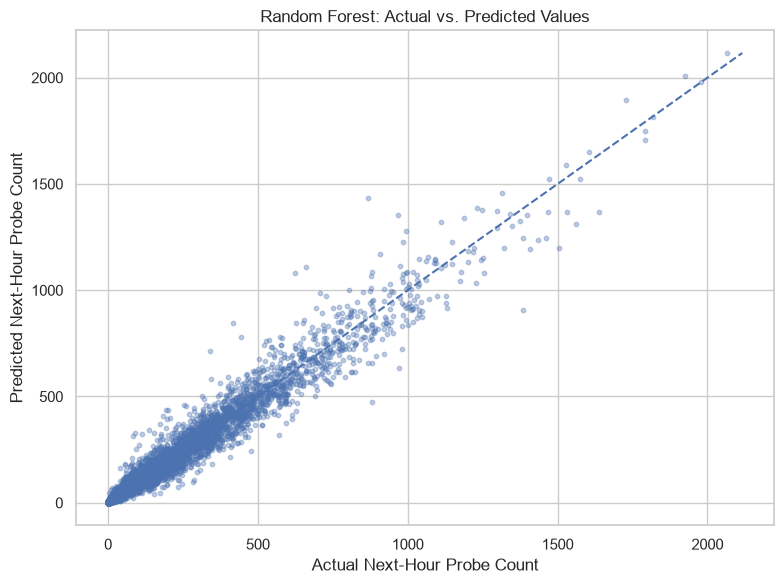

In [ ]:

import matplotlib.pyplot as plt

# Plot a sample to keep visualization responsive
plot_size = min(10_000, len(y_test))
plot_indices = y_test.sample(
    n=plot_size, random_state=42
).index

actual_values = y_test.loc[plot_indices]
predicted_values = pd.Series(
    y_pred_rf_fair, index=X_test.index
).loc[plot_indices]

plt.figure(figsize=(8, 6))
plt.scatter(actual_values, predicted_values, alpha=0.35, s=10)

# Reference line: perfect predictions
axis_min = min(actual_values.min(), predicted_values.min())
axis_max = max(actual_values.max(), predicted_values.max())
plt.plot([axis_min, axis_max], [axis_min, axis_max], linestyle="--")

plt.xlabel("Actual Next-Hour Probe Count")
plt.ylabel("Predicted Next-Hour Probe Count")
plt.title("Random Forest: Actual vs. Predicted Values")
plt.tight_layout()
plt.show()


### Task 47: Residual Analysis for Random Forest Regression

Residual analysis examines the differences between actual and predicted next-hour probe counts. A residual plot helps identify systematic prediction errors, changing error variability, and potential outliers.

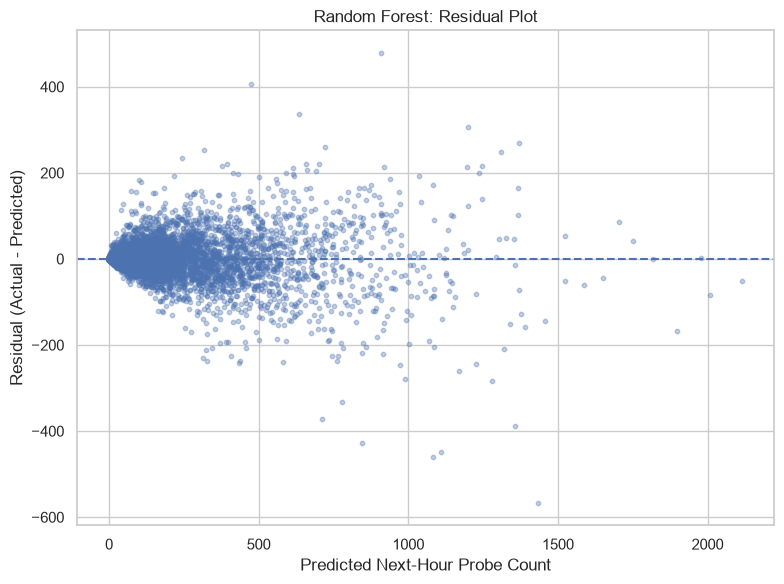

In [ ]:

# Task 47: Plot Random Forest residuals on a sample of test observations

residuals = actual_values - predicted_values

plt.figure(figsize=(8, 6))
plt.scatter(predicted_values, residuals, alpha=0.35, s=10)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Next-Hour Probe Count")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest: Residual Plot")
plt.tight_layout()
plt.show()


### Task 48: Final Model Evaluation Summary

This task summarizes the performance of Linear Regression, Polynomial Regression, and Random Forest Regression using the same 500,000 training observations and the same chronological test set. The models are compared using MAE, RMSE, and R² to identify the best-performing model for next-hour probe-count prediction.'

In [ ]:

# Task 48: Summarize the fair model comparison

final_model_summary = fair_comparison_df.sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

print("Final Model Evaluation Summary")
print(final_model_summary.to_string(index=False))

best_model_name = final_model_summary.loc[0, "Model"]
print(f"\nBest model based on RMSE: {best_model_name}")


Final Model Evaluation Summary
                   Model  Training Observations     MAE    RMSE     R2
Random Forest Regression                 500000 19.7777 39.1660 0.9633
   Polynomial Regression                 500000 22.5873 43.0991 0.9556
       Linear Regression                 500000 24.9526 46.8399 0.9475

Best model based on RMSE: Random Forest Regression


### Task 49: Random Forest Feature Importance Analysis

This task examines the feature importance scores learned by the Random Forest model. The scores help identify which predictors contribute most to the model's predictions of next-hour probe counts. Feature importance indicates predictive usefulness, not causation.

Top 10 Most Important Features:
                   Feature  Importance
                probeCount    0.670033
         probeCount_lag_24    0.155198
          probeCount_lag_1    0.083442
probeCount_rolling_mean_3h    0.049094
          probeCount_lag_2    0.008898
                  hour_cos    0.008474
                  hour_sin    0.006593
                      hour    0.004400
 probeCount_rolling_std_3h    0.003226
          probeCount_lag_3    0.002832


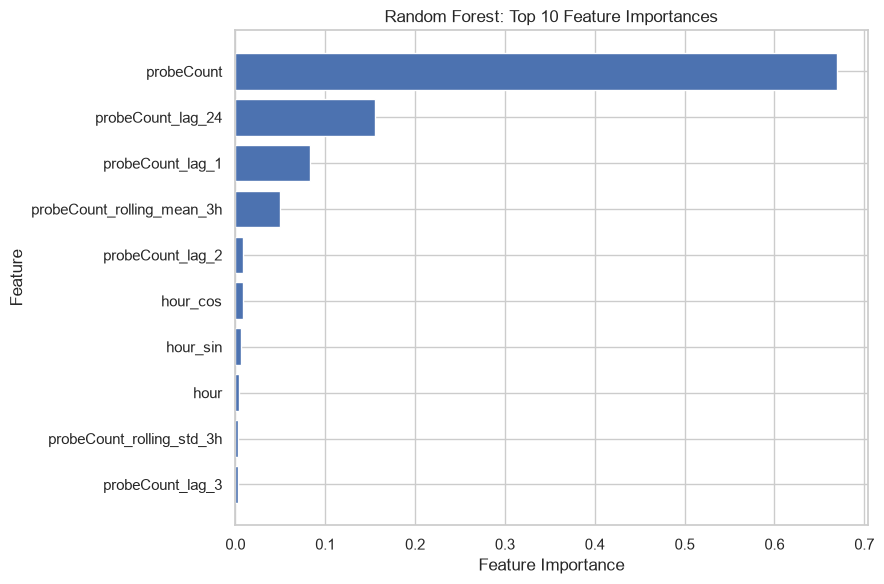

In [ ]:

# Task 49: Inspect and visualize Random Forest feature importance

feature_importance_df = pd.DataFrame({
    "Feature": X_common_train.columns,
    "Importance": fair_rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance_df.head(10).to_string(index=False))

top_features = feature_importance_df.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest: Top 10 Feature Importances")
plt.tight_layout()
plt.show()


### Task 50: Save the Final Trained Random Forest Model

The Random Forest Regression model achieved the best results among the three evaluated models. In this task, we save the trained model and its required feature information so that it can be reused in the project prototype without retraining.

In [ ]:

# Task 50: Save the trained Random Forest model and feature information

import joblib
import json
from pathlib import Path

# Create a folder for saved project artifacts
model_dir = Path("saved_model")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model
joblib.dump(fair_rf_model, model_dir / "random_forest_model.joblib")

# Save the exact feature order expected by the model
model_features = list(X_common_train.columns)

with open(model_dir / "model_features.json", "w") as file:
    json.dump(model_features, file, indent=4)

# Save the evaluation metrics
model_metrics = {
    "model": "Random Forest Regression",
    "training_observations": 500000,
    "MAE": float(fair_comparison_df.loc[
        fair_comparison_df["Model"] == "Random Forest Regression", "MAE"
    ].iloc[0]),
    "RMSE": float(fair_comparison_df.loc[
        fair_comparison_df["Model"] == "Random Forest Regression", "RMSE"
    ].iloc[0]),
    "R2": float(fair_comparison_df.loc[
        fair_comparison_df["Model"] == "Random Forest Regression", "R2"
    ].iloc[0])
}

with open(model_dir / "model_metrics.json", "w") as file:
    json.dump(model_metrics, file, indent=4)

print("Model artifacts saved successfully.")
print("Saved files:")
for file_path in sorted(model_dir.iterdir()):
    print(f"- {file_path}")
print(f"\nNumber of required features: {len(model_features)}")


Model artifacts saved successfully.
Saved files:
- saved_model\model_features.json
- saved_model\model_metrics.json
- saved_model\random_forest_model.joblib

Number of required features: 17


### Task 51: Verify the Saved Random Forest Model

This task verifies that the saved Random Forest model can be loaded and used to generate predictions. Its predictions will be compared with those from the original trained model to confirm that saving and reloading preserved the model.

In [ ]:

# Task 51: Reload and verify the saved model

import joblib
import numpy as np
from pathlib import Path

model_path = Path("saved_model") / "random_forest_model.joblib"
loaded_rf_model = joblib.load(model_path)

# Generate predictions using the reloaded model
loaded_predictions = loaded_rf_model.predict(X_test.iloc[:100])

# Compare with predictions from the original model
original_predictions = fair_rf_model.predict(X_test.iloc[:100])

predictions_match = np.allclose(
    loaded_predictions, original_predictions
)

print("Saved model loaded successfully.")
print("Number of predictions:", len(loaded_predictions))
print("Predictions match original model:", predictions_match)
print("First 5 predictions:", np.round(loaded_predictions[:5], 4))


Saved model loaded successfully.
Number of predictions: 100
Predictions match original model: True
First 5 predictions: [0.2935 0.2575 0.0995 0.085  0.1486]



## Task 52: Build the Working Prototype Using Streamlit

This task develops a simple interactive web application for the Smart Traffic Congestion Prediction Using Machine Learning project.

The application uses the saved Random Forest Regression model and its associated feature metadata and evaluation metrics. It allows users to enter the current probe count, historical probe counts, prediction time, and road-segment characteristics to predict the next-hour probe count.

The prototype recreates the feature engineering used during model development, including lag features, three-hour rolling statistics, and cyclical time features. The input features are arranged in the exact order expected by the saved model.

The application displays the saved model's evaluation metrics and the predicted next-hour probe count. It also provides an option to inspect the input features used for a prediction.

The model is loaded from the existing saved artifacts, so model training is not repeated. The prediction represents a numerical probe count for the same road segment, rather than a direct vehicle count or a predefined congestion category.


In [ ]:

%%writefile app.py

import json
from datetime import date, datetime, time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st


# ==================================================
# 1. PAGE CONFIGURATION
# ==================================================

st.set_page_config(
    page_title="Smart Traffic Congestion Prediction",
    page_icon="🚦",
    layout="wide"
)

st.title("Smart Traffic Congestion Prediction")
st.subheader("Random Forest Regression Prototype")

st.write(
    "Predict the next-hour probe count for a road segment "
    "using historical traffic observations and road characteristics."
)


# ==================================================
# 2. LOAD SAVED MODEL ARTIFACTS
# ==================================================

PROJECT_DIR = Path(__file__).resolve().parent
MODEL_DIR = PROJECT_DIR / "saved_model"

MODEL_PATH = MODEL_DIR / "random_forest_model.joblib"
FEATURES_PATH = MODEL_DIR / "model_features.json"
METRICS_PATH = MODEL_DIR / "model_metrics.json"


@st.cache_resource
def load_model_artifacts():
    required_paths = [
        MODEL_PATH,
        FEATURES_PATH,
        METRICS_PATH
    ]

    missing = [
        path.name for path in required_paths
        if not path.exists()
    ]

    if missing:
        raise FileNotFoundError(
            "Required files are missing from saved_model: "
            + ", ".join(missing)
        )

    model = joblib.load(MODEL_PATH)

    with open(FEATURES_PATH, "r", encoding="utf-8") as file:
        feature_names = json.load(file)

    with open(METRICS_PATH, "r", encoding="utf-8") as file:
        metrics = json.load(file)

    if len(feature_names) != model.n_features_in_:
        raise ValueError(
            "Saved feature count does not match the model."
        )

    return model, feature_names, metrics


try:
    model, feature_names, metrics = load_model_artifacts()
    st.success("Saved Random Forest model loaded successfully.")

except Exception as error:
    st.error(f"Unable to load model artifacts: {error}")
    st.stop()


# ==================================================
# 3. DISPLAY MODEL PERFORMANCE
# ==================================================

st.markdown("### Saved Model Performance")

col1, col2, col3 = st.columns(3)

col1.metric("MAE", f"{metrics['MAE']:.4f}")
col2.metric("RMSE", f"{metrics['RMSE']:.4f}")
col3.metric("R²", f"{metrics['R2']:.4f}")

st.caption(
    "These metrics are loaded from the saved evaluation results. "
    "The model is not retrained by this application."
)


# ==================================================
# 4. COLLECT PREDICTION INPUTS
# ==================================================

st.markdown("### Enter Traffic Information")

with st.form("prediction_form"):

    st.markdown("#### Observation date and time")

    date_col, time_col = st.columns(2)

    with date_col:
        observation_date = st.date_input(
            "Current observation date",
            value=date.today()
        )

    with time_col:
        observation_time = st.time_input(
            "Current observation hour",
            value=time(12, 0)
        )

    st.markdown("#### Probe-count history")

    left, right = st.columns(2)

    with left:
        current_count = st.number_input(
            "Current-hour probe count",
            min_value=0.0,
            value=100.0,
            step=1.0
        )

        lag_1 = st.number_input(
            "Probe count 1 hour earlier",
            min_value=0.0,
            value=95.0,
            step=1.0
        )

        lag_2 = st.number_input(
            "Probe count 2 hours earlier",
            min_value=0.0,
            value=90.0,
            step=1.0
        )

    with right:
        lag_3 = st.number_input(
            "Probe count 3 hours earlier",
            min_value=0.0,
            value=85.0,
            step=1.0
        )

        lag_24 = st.number_input(
            "Probe count 24 hours earlier",
            min_value=0.0,
            value=80.0,
            step=1.0
        )

    st.markdown("#### Road-segment characteristics")

    road1, road2, road3 = st.columns(3)

    with road1:
        speed_limit = st.number_input(
            "Speed limit (dataset units)",
            min_value=0.0,
            value=50.0,
            step=1.0
        )

    with road2:
        frc = st.number_input(
            "Functional road class (frc)",
            min_value=0.0,
            value=3.0,
            step=1.0
        )

    with road3:
        distance = st.number_input(
            "Segment distance (dataset units)",
            min_value=0.0,
            value=1.0,
            step=0.1
        )

    submitted = st.form_submit_button(
        "Predict Next-Hour Probe Count",
        use_container_width=True
    )


# ==================================================
# 5. FEATURE ENGINEERING
# ==================================================

if submitted:

    timestamp = datetime.combine(
        observation_date,
        observation_time
    )

    hour = timestamp.hour
    day_of_week = timestamp.weekday()
    is_weekend = int(day_of_week >= 5)

    # Cyclical encoding of hour and day of week.
    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)

    day_of_week_sin = np.sin(
        2 * np.pi * day_of_week / 7
    )

    day_of_week_cos = np.cos(
        2 * np.pi * day_of_week / 7
    )

    # Match the notebook's shifted three-observation window.
    # The current observation is excluded.
    previous_counts = np.array(
        [lag_1, lag_2, lag_3],
        dtype=float
    )

    rolling_mean_3h = float(
        np.mean(previous_counts)
    )

    # pandas rolling.std() uses ddof=1 by default.
    rolling_std_3h = float(
        np.std(previous_counts, ddof=1)
    )

    # Create the features used by the trained model.
    feature_values = {
        "probeCount": current_count,
        "probeCount_lag_1": lag_1,
        "probeCount_lag_2": lag_2,
        "probeCount_lag_3": lag_3,
        "probeCount_lag_24": lag_24,
        "probeCount_rolling_mean_3h": rolling_mean_3h,
        "probeCount_rolling_std_3h": rolling_std_3h,
        "hour": hour,
        "day_of_week": day_of_week,
        "is_weekend": is_weekend,
        "hour_sin": hour_sin,
        "hour_cos": hour_cos,
        "day_of_week_sin": day_of_week_sin,
        "day_of_week_cos": day_of_week_cos,
        "speedLimit": speed_limit,
        "frc": frc,
        "distance": distance
    }

    # Preserve the exact feature order from model metadata.
    try:
        input_df = pd.DataFrame(
            [[feature_values[name] for name in feature_names]],
            columns=feature_names
        )
    except KeyError as error:
        st.error(f"Required model feature is missing: {error}")
        st.stop()

    if not np.isfinite(input_df.to_numpy(dtype=float)).all():
        st.error("The input features contain invalid values.")
        st.stop()


    # ==================================================
    # 6. GENERATE PREDICTION
    # ==================================================

    try:
        prediction = float(model.predict(input_df)[0])

        st.markdown("---")
        st.markdown("### Prediction Result")

        result1, result2 = st.columns(2)

        result1.metric(
            "Predicted next-hour probe count",
            f"{prediction:,.2f}"
        )

        result2.write("**Observation timestamp**")
        result2.write(timestamp.strftime("%Y-%m-%d %H:%M"))
        result2.write("**Forecast horizon**")
        result2.write("Next hourly observation")

        st.info(
            "This model predicts a numerical probe count. "
            "It does not directly predict a formal congestion category "
            "or an exact number of vehicles."
        )

        with st.expander("View all 17 model input features"):
            st.dataframe(input_df, use_container_width=True)

    except Exception as error:
        st.error(f"Prediction failed: {error}")


# ==================================================
# 7. PROJECT INFORMATION
# ==================================================

with st.expander("About this project"):

    st.write(
        "**Project:** Smart Traffic Congestion Prediction "
        "Using Machine Learning"
    )

    st.write(
        "**Dataset:** New Delhi Traffic Probe & Analytics Dataset (2024)"
    )

    st.write("**Selected model:** Random Forest Regression")

    st.write(
        "**Target:** Next-hour probe count for the same road segment"
    )


Overwriting app.py



### Running the Streamlit Application

The application is saved as `app.py` in the project directory.

To launch the prototype, open PowerShell in the project directory, activate the existing virtual environment, and execute:

```powershell
streamlit run app.py
```

The application opens in a browser. Users can enter traffic and road-segment information, generate a next-hour probe-count prediction, and inspect the model input features.

The prototype uses the saved model and does not repeat model training.


### Task 52: Prototype Execution and Prediction Test

The Streamlit prototype was launched successfully using the saved Random Forest Regression model. The application loaded the saved model artifacts and displayed the stored evaluation metrics without repeating model training.

A test prediction was generated using illustrative traffic and road-segment inputs. The application returned a predicted next-hour probe count of **96.17** for the observation timestamp `2026-10-18 12:00`.

The prototype also displayed the 17 input features used by the model, confirming that the prediction interface constructs the model input in the expected feature order.

**Outcome:** The initial prototype execution and prediction test were successful.

**Limitation:** The prediction is a numerical probe count. It does not directly classify traffic congestion levels or represent an exact number of vehicles. The test used illustrative inputs and does not establish real-time forecasting performance.